# Proyecto 1 — Sacarle al EEG el ruido de los ojos (EOG) y de los músculos (EMG) con NLMS

**Cómo leer este notebook:** esta primera parte explica el problema y la idea, sin código. Después, cada sección empieza con un recuadro **"Dónde estamos"**, que dice qué pregunta responde esa sección. Debajo de cada gráfico hay un **"Qué mirar"** que explica por qué se dibujó y qué conclusión sale.

---

## 1. El problema

### 1.1 Qué mide un electrodo
Un electrodo pegado en la cabeza no mide solo al cerebro. Mide la **suma** de tres cosas:

- **`s(n)`, el EEG:** la actividad del cerebro. Es lo que queremos. Es muy chico: decenas de µV.
- **`η_EOG(n)`, el ruido de los ojos:** el ojo funciona como una pila (la córnea es positiva respecto de la retina). Cuando los ojos se mueven o parpadean, ese campo eléctrico cambia y llega a los electrodos de la frente. Es grande (hasta cientos de µV) y **lento**: casi todo está por debajo de ~15 Hz.
- **`η_EMG(n)`, el ruido de los músculos:** cuando se contrae un músculo (mandíbula, sien, cuello), genera una señal eléctrica **rápida** (más de 20 Hz). Aparece en **ráfagas**: nada durante un rato y de golpe una explosión.

Entonces lo que se graba es

`y(n) = s(n) + λ₁·η_EOG(n) + λ₂·η_EMG(n)`

donde `λ₁` y `λ₂` dicen cuánto de cada ruido llega a *ese* electrodo: cuanto más cerca de la fuente, más grande. **El objetivo es recuperar `s(n)` a partir de `y(n)`.**

### 1.2 Por qué no alcanza con un filtro común
Si el ruido estuviera en frecuencias donde no hay EEG, un pasa-banda lo sacaría y listo. El problema es que **se pisan**:
- el EOG (< 15 Hz) cae encima de las bandas δ, θ y α del EEG;
- el EMG (> 20 Hz) cae encima de β y γ.

Un filtro que saque el EOG también se lleva el EEG de esas frecuencias.

### 1.3 La idea: cancelación adaptativa de ruido
Funciona como los auriculares con cancelación de ruido: un micrófono de afuera escucha *solo el ruido*, el auricular arma una copia del ruido tal como llega al oído, y la resta.

Acá es igual. Si tenemos un sensor que mide (casi) solo el ruido, al que llamamos **referencia** `x(n)`:
1. pasamos la referencia por un filtro `w` que la convierte en "el ruido tal como llega al electrodo". A esa estimación la llamamos `ŷ(n)`;
2. la restamos: `e(n) = y(n) − ŷ(n)`.

Si `ŷ` es igual al ruido que hay en `y`, lo que queda es `e(n) = s(n)`: **el EEG limpio**.

**¿Cómo encuentra el filtro el `w` correcto?** Va ajustando `w` para que `e(n)` sea lo más chico posible.

**¿Y eso no borra también el EEG?** No, mientras la referencia no tenga EEG. El filtro solo puede armar cosas a partir de la referencia. Si en la referencia no hay EEG, no puede armar EEG para restarlo. Lo único que puede achicar es la parte de ruido, y el EEG queda en `e(n)` (principio de ortogonalidad, `6. LMS.pdf`).

**El riesgo:** si la referencia sí trae algo de EEG, el filtro puede restar EEG bueno. Esto aparece más adelante.

### 1.4 El diagrama en bloques

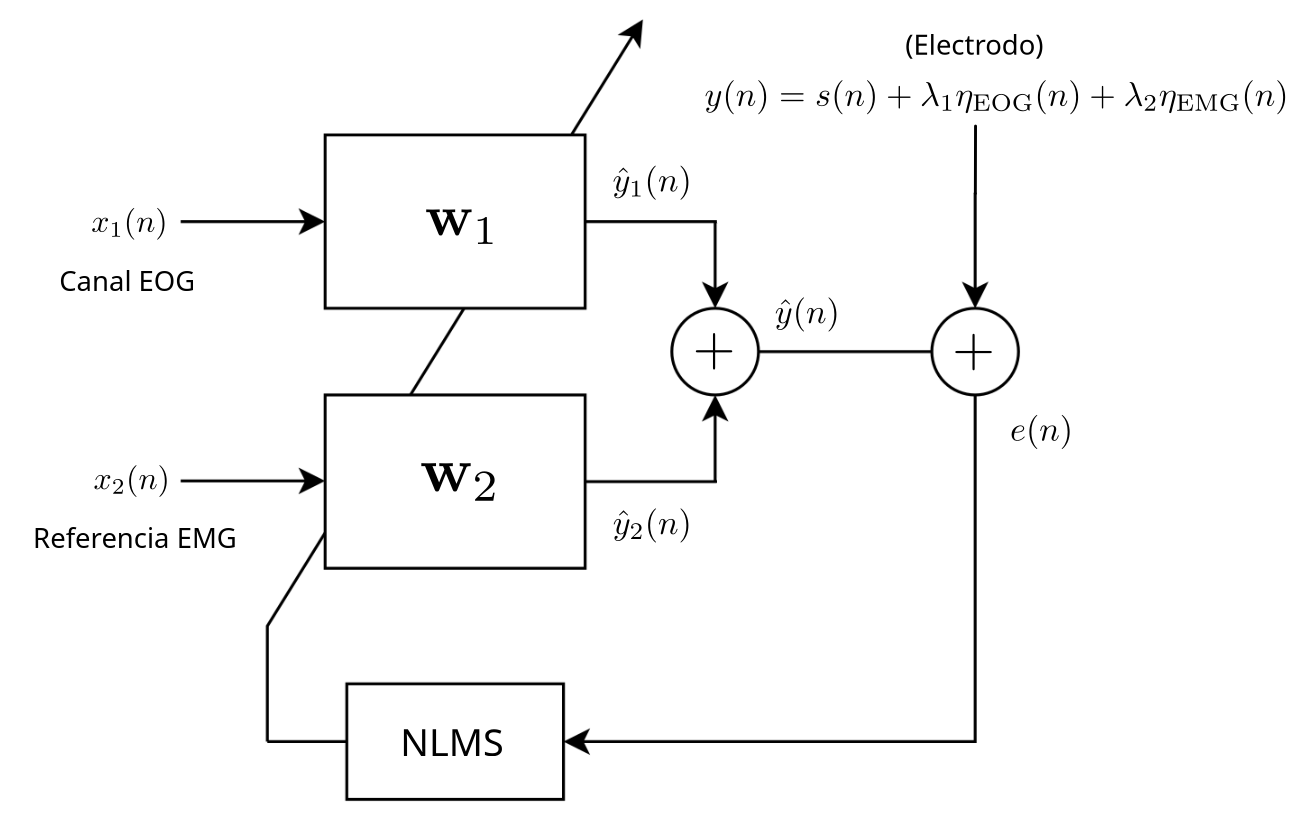

### 1.5 Qué es cada señal en este dataset

| Símbolo | Qué es acá |
|---|---|
| `y(n)` | Un canal de EEG tal como se grabó (Fp1, F7, F8, T8 u Oz). |
| `x₁(n)` | El canal **EOG** del dataset: un electrodo cerca del ojo. |
| `x₂(n)` | El dataset **no tiene canal de EMG**, así que lo armamos con los electrodos más cercanos a la mandíbula y la sien: `T9, TP9, FT9` (izquierda) y `T10, TP10, FT10` (derecha). Promediamos los tres de cada lado y les aplicamos un pasa-altos en 25 Hz: el EMG está arriba de 20 Hz, y así sacamos el EEG lento que también miden esos electrodos. Quedan **dos referencias de EMG** (izquierda y derecha), o sea 3 referencias en total. |
| `w` | Tres filtros de M = 3 coeficientes, uno por referencia, juntos en un solo vector de 9 números. |
| NLMS | La regla que ajusta `w` en cada muestra. |
| `e(n)` | La salida: nuestra estimación del EEG limpio. |

**Importante:** hay **una sola** señal de error, `e(n)`, y ajusta todos los coeficientes a la vez. EOG y EMG no son "dos errores": son dos *ruidos*, cada uno con su referencia.

---

## 2. El problema de fondo: ¿cómo sabemos si salió bien?
Para saber si `e(n)` es el EEG limpio, lo natural sería compararlo con `s(n)`. Pero **en una grabación real nadie conoce `s(n)`**: solo tenemos `y(n)`. Eso es lo que significa "no hay ground truth". Por eso el notebook va por dos caminos.

**Camino A, experimento semi-sintético (§4).** Armamos la mezcla nosotros:
- tomamos un pedazo de EEG que ya está limpio y lo llamamos `s`;
- le sumamos ruido real de *otra* grabación, en la cantidad que elegimos;
- se lo damos al filtro.

Como `s` lo elegimos nosotros, lo conocemos, y podemos medir exactamente cuánto se parece `e` a `s`. De acá salen los números confiables (curva de aprendizaje, desajuste, error relativo…). La limitación es que la mezcla armada puede ser más fácil que la real.

**Camino B, datos reales (§5 y §6).** Corremos el filtro sobre la grabación cruda. No podemos comparar `e` con `s`. En cambio, nos preguntamos **"si el filtro anduviera bien, ¿qué tendría que pasar?"** y lo comprobamos. Por ejemplo:
- el ruido de los ojos tendría que desaparecer de `e`;
- el ritmo α del cerebro no tendría que cambiar;
- un canal lejos de ojos y músculos no tendría que cambiar.

Ninguna prueba sola alcanza, pero si todas coinciden, le podemos creer.

---

## 3. Mapa del notebook

| Sección | Pregunta que responde | Camino |
|---|---|---|
| §1 Carga | ¿Cómo leo los datos? | — |
| §2 Inspección | ¿Qué ruido hay *realmente* en este sujeto? (decide todo lo demás) | — |
| §3 El filtro | El código de NLMS y de Wiener | — |
| §4 Semi-sintético | ¿El filtro funciona? ¿Con qué μ̃ y M? | A |
| §5 Datos reales | ¿Qué hace el filtro sobre la grabación cruda? | B |
| §6 Validación | ¿Le creemos a `e(n)` en los datos reales? | B |
| §7 Conclusiones | ¿Obtuvimos un EEG limpio? | — |
| §8 VS-LMS y compuerta | ¿Mejora con VS-LMS y con un filtro de EMG que solo actúa en las ráfagas? | A y B |

**Resumen de resultados** (el detalle está en cada sección):
- El filtro está bien ajustado y, en el caso armado, limpia: con $\~{\mu} = 0.03$ y $M = 3$ el error relativo baja de 2.0 a 0.67.
- Este dataset viene **preprocesado**: ya le sacaron los parpadeos al EEG. Quedan movimientos de ojos hacia los costados y algunas ráfagas de músculo.
- En los datos reales **todavía no podemos afirmar** que `e` sea EEG limpio:
  - las ráfagas de músculo se van bien;
  - pero el filtro también saca alta frecuencia donde no hay músculo;
  - y a veces resta *de más* el ruido de los ojos.

In [ ]:
import glob
import numpy as np
import pandas as pd
import mne
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, lfilter, welch, find_peaks

mne.set_log_level("ERROR")

# Parámetros
RAIZ = "./datasets-presentacion-PASA/ds008701"
SUJETO = "01"
FS = 250                    # Submuestreo 1000 -> 250 Hz: la banda grabada termina en ~80 Hz
T_INI, T_FIN = 10, 110      # Ventana útil [s]: los bordes tienen derivas de varios mV
CANALES_EMG_IZQ = ["T9", "TP9", "FT9"]
CANALES_EMG_DER = ["T10", "TP10", "FT10"]
CANALES_REF = ["EOG"] + CANALES_EMG_IZQ + CANALES_EMG_DER
F_HP_EMG = 25               # Pasa-altos de la referencia de EMG [Hz]: saca δ–α del EEG

## §1. Carga de los datos

> **Dónde estamos:** todavía no filtramos nada. Solo leemos las grabaciones y las dejamos listas.

**Qué hay en el disco:**
- El sujeto 01 escuchó 20 canciones. Cada carpeta `ses-tXX` es **una canción**, no una sesión en el tiempo.
- Cada grabación tiene 66 canales de EEG y 1 de EOG, a 1000 muestras por segundo, en voltios.

**Qué hace el código:**
- Lee los archivos `.set` con MNE. Qué canal es EOG se lee de `channels.tsv`, porque MNE marca todos como EEG.
- Pasa todo a µV.
- **Recorta a 10–110 s.** Los primeros y últimos segundos tienen derivas enormes (de mV) que no son ni EEG ni ruido útil. Si se las damos al filtro, se dedica a seguir eso.
- **Baja a 250 muestras por segundo.** La grabación ya viene filtrada y no tiene nada arriba de ~80 Hz (lo vas a ver en la PSD de §2.2). Con 250 muestras/s alcanza (Nyquist = 125 Hz > 80 Hz), y el filtro hace 4 veces menos cuentas.
- Saca la continua (el promedio) de cada canal.

**Resultado:** `DATOS[canción][canal]` es un arreglo de 25 001 muestras (100 s) en µV.

In [ ]:
def ruta_set(ses):
    return f"{RAIZ}/sub-{SUJETO}/ses-{ses}/eeg/sub-{SUJETO}_ses-{ses}_task-music_eeg.set"


def cargar(ses, fs=FS):
    """Carga una canción: dict {canal: señal en µV}, recortada a [T_INI, T_FIN] y submuestreada a fs."""
    raw = mne.io.read_raw_eeglab(ruta_set(ses), preload=True)
    raw.crop(T_INI, T_FIN)
    raw.resample(fs)                        # MNE aplica el antialias
    X = raw.get_data() * 1e6                # V -> µV
    X = X - X.mean(axis=1, keepdims=True)   # Sin continua
    return dict(zip(raw.ch_names, X))


SESIONES = sorted(p.split("/")[-3][4:] for p in glob.glob(f"{RAIZ}/sub-{SUJETO}/ses-*/eeg/*_eeg.set"))

base_ses = f"{RAIZ}/sub-{SUJETO}/ses-t01/eeg/sub-{SUJETO}_ses-t01"
canales_tsv = pd.read_csv(f"{base_ses}_task-music_channels.tsv", sep="\t", encoding="utf-8-sig")
electrodos = pd.read_csv(f"{base_ses}_space-CapTrak_electrodes.tsv", sep="\t", encoding="utf-8-sig", na_values="n/a")
tipos = dict(zip(canales_tsv["name"], canales_tsv["type"]))
CANALES_EEG = [c for c, t in tipos.items() if t == "EEG"]

DATOS = {ses: cargar(ses) for ses in SESIONES}

print(f"{len(SESIONES)} canciones: {SESIONES}")
print(f"{len(CANALES_EEG)} canales EEG + {sum(t == 'EOG' for t in tipos.values())} EOG, "
      f"{len(DATOS[SESIONES[0]]['Oz']) / FS:.1f} s por canción a {FS} Hz")

## §2. Inspección: ¿qué ruido hay realmente?

> **Dónde estamos:** antes de diseñar el filtro hay que saber contra qué peleamos. Si el EEG no tiene ruido de ojos, no hay nada que cancelar. Si los canales temporales no tienen EMG, no sirven como referencia.

**Las preguntas, y con qué herramienta se responde cada una:**

1. **¿El ruido de los ojos aparece en el EEG?** Se mide la **correlación** entre el canal EOG y cada canal de EEG.
   - La correlación es un número entre −1 y 1 que dice cuánto se mueven juntas dos señales.
   - ≈ 0 es que no tienen nada que ver; cerca de 1, que suben y bajan juntas; cerca de −1, que una sube cuando la otra baja.
   - El filtro **solo puede sacar el EOG de los canales que se parecen al EOG**.
2. **¿Hay parpadeos?** Un parpadeo es un pico grande y corto en el EOG. Los contamos con un umbral. El código los llama "parpadeos", pero en realidad cuenta cualquier evento grande del EOG, incluidos los movimientos de ojos.
3. **¿Hay EMG en los canales temporales?** El EMG viene en ráfagas. Para detectarlo:
   - nos quedamos con lo que está arriba de 30 Hz, que es donde está el EMG;
   - calculamos la **envolvente**: el "tamaño" de la señal a lo largo del tiempo;
   - medimos su **curtosis**, un número que dice qué tan "picuda" es una señal. Un ruido parejo da ≈ 3; una señal tranquila con algunas explosiones da mucho más que 3;
   - miramos si las ráfagas pasan a la vez a la izquierda y a la derecha (correlación entre las dos envolventes).

En esta celda también se arman las referencias de EMG (`EMG_IZQ`, `EMG_DER`) que se usan en el resto del notebook.

In [ ]:
sos_lp10 = butter(4, 10, "low", fs=FS, output="sos")
sos_hp30 = butter(4, 30, "high", fs=FS, output="sos")
sos_lp2 = butter(4, 2, "low", fs=FS, output="sos")
sos_hp_emg = butter(4, F_HP_EMG, "high", fs=FS, output="sos")


def envolvente_hf(x):
    """Envolvente de la parte > 30 Hz (indicador de EMG)."""
    return sosfiltfilt(sos_lp2, np.abs(sosfiltfilt(sos_hp30, x)))


def curtosis(x):
    x = x - x.mean()
    return np.mean(x**4) / np.mean(x**2)**2


def detectar_parpadeos(eog):
    """Picos del EOG pasa-bajos que superan 4 desvíos robustos (MAD)."""
    eog_lp = sosfiltfilt(sos_lp10, eog)
    umbral = 4 * np.median(np.abs(eog_lp)) / 0.6745
    picos, _ = find_peaks(np.abs(eog_lp), height=umbral, distance=int(0.3 * FS))
    return picos, eog_lp


def ref_emg(c, canales):
    """Referencia de EMG: promedio de los canales de un lado, pasa-altos en F_HP_EMG."""
    return sosfiltfilt(sos_hp_emg, np.mean([c[n] for n in canales], axis=0))


EMG_IZQ = {ses: ref_emg(c, CANALES_EMG_IZQ) for ses, c in DATOS.items()}
EMG_DER = {ses: ref_emg(c, CANALES_EMG_DER) for ses, c in DATOS.items()}

filas = []
for ses, c in DATOS.items():
    picos, _ = detectar_parpadeos(c["EOG"])
    corr = {n: np.corrcoef(c["EOG"], c[n])[0, 1] for n in CANALES_EEG}
    n_max = max(corr, key=lambda n: abs(corr[n]))
    env_izq, env_der = envolvente_hf(EMG_IZQ[ses]), envolvente_hf(EMG_DER[ses])
    filas.append(dict(sesion=ses, parpadeos=len(picos), std_EOG=c["EOG"].std(), std_Fp1=c["Fp1"].std(),
                      corr_EOG_Fp1=corr["Fp1"], corr_EOG_max=corr[n_max], canal_max=n_max,
                      kurt_emg_izq=curtosis(env_izq), kurt_emg_der=curtosis(env_der),
                      corr_env_izq_der=np.corrcoef(env_izq, env_der)[0, 1]))

tabla = pd.DataFrame(filas).set_index("sesion")
print(tabla.round(2).to_string())

### Qué mirar en la tabla

Cada fila es una canción. Las columnas:
- `parpadeos`: cantidad de eventos grandes del EOG.
- `std_EOG`, `std_Fp1`: tamaño típico (desvío estándar) en µV. El EOG es unas 5 veces más grande que el EEG.
- `corr_EOG_Fp1`: correlación del EOG con Fp1, el electrodo justo arriba del ojo izquierdo.
- `corr_EOG_max`, `canal_max`: el canal de EEG que más se parece al EOG, y cuánto.
- `kurt_emg_izq`, `kurt_emg_der`: curtosis de la envolvente de cada referencia de EMG (mucho más que 3 = hay ráfagas).
- `corr_env_izq_der`: si las ráfagas pasan a la vez de los dos lados.

**Qué sale:**
- El canal que más se parece al EOG casi siempre es **F7, con signo +, o F8, con signo −**. F7 está al costado del ojo izquierdo y F8 al costado del derecho.
- Que tengan signos opuestos es justo lo que pasa cuando los ojos **miran hacia un costado**: un lado se hace positivo y el otro negativo. Conclusión: **en el EEG quedó ruido de movimientos oculares horizontales**. La canción con más es **t17** (r ≈ 0.6).
- Correlaciones de 0.2 a 0.6 no son enormes: el ruido de ojos está, pero es una parte del EEG, no la mayor parte.
- La curtosis del EMG es mucho más que 3 **solo en t04, t07, t15 y t25**: ahí hay ráfagas de músculo. La que más tiene es **t15**. En las demás canciones, las referencias de EMG son ruido parejo.
- Las ráfagas pasan a la vez de los dos lados (correlación de hasta 1.0). Es algo que mueve los dos lados juntos: apretar la mandíbula o tragar.

In [ ]:
# ============================================================
# 2.1 EOG vs frontales: ¿queda EOG en el EEG?
# ============================================================

SES_EOG = tabla["corr_EOG_max"].abs().idxmax()      # Canción donde el EOG más se ve en el EEG
c = DATOS[SES_EOG]
t = np.arange(len(c["EOG"])) / FS + T_INI

fig, axes = plt.subplots(5, 1, figsize=(14, 9), sharex=True)
for ax, n in zip(axes, ["EOG", "F7", "F8", "Fp1", "Oz"]):
    ax.plot(t, c[n], linewidth=0.5)
    ax.set_ylabel(f"{n} [µV]")
    ax.grid(True)
axes[0].set_title(f"sub-{SUJETO} ses-{SES_EOG}")
axes[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: el ruido de los ojos a simple vista (t17)

**Por qué está:** para ver con los ojos lo que la tabla dijo con números, en la canción con más ruido de ojos.
- **Arriba, el EOG:** subidas y bajadas de 100–200 µV que duran alrededor de 1 s. Son movimientos de ojos.
- **F7 sigue al EOG** (cuando el EOG sube, F7 sube) y **F8 hace lo contrario** (cuando el EOG sube, F8 baja). Mirá por ejemplo alrededor de 29 s, 79 s y 86 s. **Ese es el ruido que queremos sacar.**
- **Fp1** también sigue al EOG.
- **Oz**, atrás de la cabeza y lejos de los ojos, no muestra nada de eso: es solo EEG. Por eso más adelante usamos Oz como "EEG limpio".
- **Fijate en los tamaños:** en el EOG los eventos llegan a ±200 µV, pero en F7 y F8 llegan solo a ±50 µV. A cada electrodo llega una *fracción* del ruido del ojo. Esa fracción (el `λ` de `y = s + λη`) es lo que el filtro tiene que aprender.

In [ ]:
# Promedio sincronizado con los eventos del EOG
VENTANA = int(0.5 * FS)


def promedio_sincronizado(x, picos, signo):
    """Promedio de x alrededor de cada evento (alineado en signo)."""
    tramos = [x[k - VENTANA:k + VENTANA] * s for k, s in zip(picos, signo) if VENTANA <= k < len(x) - VENTANA]
    return np.mean(tramos, axis=0)


picos, eog_lp = detectar_parpadeos(c["EOG"])
signo = np.sign(eog_lp[picos])
tau = np.arange(-VENTANA, VENTANA) / FS

fig, ax = plt.subplots(figsize=(10, 4))
for n in ["EOG", "F7", "F8", "Fp1", "Oz"]:
    ax.plot(tau, promedio_sincronizado(c[n], picos, signo), label=n)
ax.set_xlabel("t respecto del evento [s]")
ax.set_ylabel("µV")
ax.set_title(f"Promedio sincronizado con {len(picos)} eventos del EOG ({SES_EOG})")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### Qué mirar: el promedio sincronizado

**Qué es:** en el gráfico anterior el ruido del ojo está mezclado con todo el EEG, y cuesta ver cuánto llega a cada canal. El truco es:
1. buscar los momentos en que el EOG tiene un pico grande (los "eventos");
2. recortar 1 s alrededor de cada uno;
3. promediar esos recortes. Antes se dan vuelta los que tenían el pico negativo, para que todos apunten para arriba.

Lo que está atado al evento (el ruido del ojo) se suma en todos los recortes. El EEG, que no tiene nada que ver con el evento, a veces está arriba y a veces abajo, y en el promedio tiende a 0.

**Qué mirar:**
- **EOG:** el evento mide unos 200 µV.
- **F7 y Fp1** suben unos 20–25 µV en el mismo momento, y **F8** baja unos 20 µV. O sea, a esos canales llega alrededor del 10 % del EOG, con signo opuesto a cada lado.
- **Oz** queda plano: no le llega nada.
- **Esta figura se repite en §6 con la salida del filtro.** Si el filtro anda, en `e` las curvas de F7 y F8 deberían quedar planas, como Oz.
- Son pocos eventos (6), así que el promedio es ruidoso.

### Qué tenemos que sacar de este gráfico
- **Cuánto ruido de ojos llega a cada canal.** El evento en el EOG mide ~210 µV; a F7 y Fp1 llegan ~20–25 µV, y a F8 ~−20 µV. O sea, ~10 % del EOG. Esa fracción es el `λ` de `y = s + λη`, y es lo que el filtro tiene que aprender en `w`.
- **F7 y F8 van con signo opuesto.** F7 está a la izquierda y F8 a la derecha. Es la firma de un **movimiento horizontal de ojos**: el dipolo córnea–retina gira hacia un lado, y un costado de la cabeza se hace más positivo y el otro más negativo.
- **No son parpadeos.** El evento dura ~1 s, y a ±0.5 s el EOG todavía no volvió a la base. Un parpadeo es un pico corto (~0.3 s) y simétrico. Coincide con que el dataset viene preprocesado y le sacaron los parpadeos.
- **No hay retardo visible.** F7 y F8 empiezan a moverse a la vez que el EOG (~−0.4 s). El camino ojo → electrodo es casi instantáneo, así que alcanza con un filtro corto (M chico).
- **Oz queda plano:** no le llega nada. Por eso Oz sirve como "EEG limpio" en §4 y como control en §6.
- Es la foto del **"antes"**. En §6 se repite con `e`: si el filtro anda, los ~20 µV de F7 y F8 tienen que desaparecer.

In [ ]:
# ============================================================
# 2.2 PSD y EMG en los temporales
# ============================================================

fig, ax = plt.subplots(figsize=(10, 4))
for n in ["EOG", "Fp1", "Oz", "T9", "TP10"]:
    f, P = welch(DATOS["t01"][n], FS, nperseg=4 * FS)
    ax.semilogy(f, P, label=n, linewidth=0.8)
ax.set_xlabel("f [Hz]")
ax.set_ylabel("PSD [µV²/Hz]")
ax.set_title("PSD (t01)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### Qué mirar: la PSD, y para qué la dibujamos

**Qué es la PSD (densidad espectral de potencia):** dice **cuánta potencia tiene la señal en cada frecuencia**. El eje vertical es logarítmico: cada línea de la grilla es 100 veces más que la de abajo.

**Por qué está:** para decidir cosas del preprocesado y para elegir qué canal usar como EEG limpio. Hay que mirar cuatro detalles:
1. **La caída en ~80 Hz.** Arriba de 80 Hz la potencia cae millones de veces: la grabación ya viene filtrada y ahí no hay nada. Por eso alcanza con 250 muestras por segundo (§1). Además, del EMG solo vemos la parte de 20–80 Hz; el EMG real llega a cientos de Hz.
2. **El valle en 50 Hz.** La red eléctrica (50 Hz) mete ruido. Acá aparece como un valle, no como un pico: ya le aplicaron un notch, así que no hace falta sacarlo.
3. **El bulto en ~10 Hz en Oz.** Es el **ritmo α**, actividad típica del cerebro en la parte de atrás de la cabeza. Confirma que Oz tiene EEG real, así que es un buen candidato para `s` en §4. Además, α es la banda que vigilamos en §6: el filtro no debería tocarla.
4. **El EOG por debajo de ~2 Hz.** El EOG tiene casi toda su potencia en frecuencias muy bajas, justo donde está la banda δ del EEG. Por eso un pasa-altos no serviría: se llevaría también el EEG lento.

In [ ]:
SES_EMG = tabla["kurt_emg_der"].idxmax()                      # Canción con más ráfagas de EMG
SES_CON_EMG = list(tabla.index[tabla["kurt_emg_der"] > 10])   # Canciones con ráfagas claras
print(f"Canción con más EMG: {SES_EMG}; canciones con ráfagas: {SES_CON_EMG}")

t = np.arange(len(EMG_DER[SES_EMG])) / FS + T_INI
fig, axes = plt.subplots(3, 1, figsize=(14, 7), sharex=True)
axes[0].plot(t, EMG_IZQ[SES_EMG], linewidth=0.4)
axes[0].set_ylabel("EMG izq [µV]")
axes[1].plot(t, EMG_DER[SES_EMG], linewidth=0.4)
axes[1].set_ylabel("EMG der [µV]")
axes[2].plot(t, envolvente_hf(DATOS[SES_EMG]["Oz"]), label="Oz")
axes[2].plot(t, envolvente_hf(DATOS[SES_EMG]["T8"]), label="T8")
axes[2].set_ylabel("Envolvente >30 Hz")
axes[2].legend()
for ax in axes:
    ax.grid(True)
axes[0].set_title(f"Referencias de EMG (pasa-altos {F_HP_EMG} Hz), {SES_EMG}")
axes[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: las referencias de EMG (t15)

**Por qué está:** para comprobar que las referencias de EMG realmente "ven" músculo. Es la canción con más EMG.
- **Paneles 1 y 2, las referencias izquierda y derecha** (lo que está arriba de 25 Hz):
  - casi todo el tiempo son ruido parejo de ±10 µV;
  - en **~69 s y ~107 s** aparecen **ráfagas de ±50 µV**: son contracciones musculares;
  - aparecen a la vez de los dos lados.
- **Panel 3, la envolvente arriba de 30 Hz** en T8 (al lado de la sien derecha) y en Oz (la nuca). En las ráfagas, T8 crece mucho (de ~2 a ~25) y Oz poco (a ~7). El ruido es fuerte cerca de los músculos y débil lejos, como se espera del EMG.
- **Ojo:** fuera de las ráfagas, las referencias **no son cero**. Ese ruido parejo no es músculo: es EEG de alta frecuencia más el ruido del equipo, porque T9, T10, etc. también son electrodos de EEG. Si el filtro usa esa parte para restar, va a sacar cosas que no son EMG. Esto aparece en §5 y §6.

### Resumen de la inspección
- Los datos vienen **preprocesados**: no hay parpadeos típicos ni en el EOG ni en el EEG. Probablemente los sacaron (con ICA) antes de publicar el dataset.
- Queda ruido de **movimientos oculares horizontales** en F7, F8 y Fp1. La mejor canción para verlo es **t17**.
- Hay **EMG en ráfagas** en 4 de las 20 canciones, a la vez de los dos lados. La mejor es **t15**.
- **Oz** casi no tiene ninguno de los dos ruidos. Lo usamos como "EEG limpio" en §4 y como control en §6.
- **Consecuencia:** en los datos reales hay poco ruido para cancelar. Por eso los números confiables salen del semi-sintético (§4).

## §3. El filtro: NLMS y Wiener

> **Dónde estamos:** ya sabemos qué ruido hay. Ahora viene el bloque central del diagrama: el filtro `w` y la regla que lo ajusta.

### Qué entra al filtro
En cada instante `n`, el filtro mira las últimas M = 3 muestras de cada referencia y las pone en fila en un vector:

`x(n) = [EOG(n), EOG(n−1), EOG(n−2), EMGizq(n), EMGizq(n−1), EMGizq(n−2), EMGder(n), EMGder(n−1), EMGder(n−2)]`

Son 9 números. **¿Por qué varias muestras y no una sola?** Porque el ruido no llega al electrodo exactamente igual que a la referencia: puede llegar un poco atrasado o "suavizado". Con algunas muestras del pasado, el filtro puede armar esa versión.

### Qué hace el filtro
- `ŷ(n) = wᵀ x(n)`: una suma ponderada de esas 9 muestras. Es la estimación del ruido que hay en el electrodo.
- `e(n) = y(n) − ŷ(n)`: lo que queda. Es la estimación del EEG.

### Cómo aprende: NLMS (`7. Variantes de LMS.pdf`)

`w(n+1) = w(n) + μ̃ · x(n) · e(n) / (‖x(n)‖² + δ)`

**En palabras:** si `e(n)` quedó grande y "en la misma dirección" que `x(n)`, quedó ruido sin restar. Entonces se corrige `w` un poquito en esa dirección.
- **μ̃ (el paso):** cuánto corrige en cada muestra.
  - Grande: aprende rápido, pero "tiembla" (desajuste) y puede ponerse a seguir cosas que no debe.
  - Chico: más preciso, pero lento.
  - Es estable si 0 < μ̃ < 2.
- **La división por ‖x(n)‖²** es la "N" de NLMS. Hace que la corrección no dependa de qué tan fuerte esté la referencia en ese momento. Durante un movimiento de ojos `x` es enorme, y sin dividir (LMS común) daría un salto gigante. Por eso elegimos NLMS en la presentación.
- **δ:** un número chiquito para no dividir por cero cuando `x ≈ 0`.
- **w(0) = 0:** el filtro arranca sin restar nada.

### Wiener: lo mejor que puede hacer un filtro *fijo* (`3. Filtrado lineal óptimo.pdf`)
`wiener()` mira la grabación entera de una vez y calcula el `w` fijo que deja `e` lo más chico posible: `w_o = R⁻¹p`. No es adaptativo (necesita toda la señal de antemano), pero sirve de **regla para medir a NLMS**:
- **`J_min`:** el error que deja el mejor filtro fijo. NLMS no debería bajar mucho más que esto. Si baja, ojo: está siguiendo cosas que no debería.
- **bias:** qué tan lejos queda el `w` de NLMS del `w_o`.
- **Autovalores de R:** el aprendizaje de `w` tiene varios "modos", y cada autovalor dice qué tan rápido aprende uno. Si el **spread** (λmax/λmin) es grande, algunas partes de `w` aprenden muchísimo más lento que otras.

### Las otras funciones de la celda
- `matriz_regresores`: lo mismo que `armar_regresor`, pero para todos los `n` a la vez (la usa Wiener).
- `aportes`: separa `ŷ` en la parte que armó cada referencia (`ŷ_EOG`, `ŷ_EMG`), para poder graficarlas por separado.
- `rrmse(a, b)`: error relativo `√(promedio de (a − b)² / promedio de b²)`. 0 es que son iguales; 1 es que el error es tan grande como la señal.
- `rrmse_espectral`: lo mismo, pero comparando las PSD. Responde si las dos señales tienen la misma "forma" en frecuencia.

In [ ]:
def armar_regresor(refs, n, M):
    """x(n) = [x1(n), ..., x1(n-M+1), x2(n), ..., x2(n-M+1), ...]^T (ceros antes de n = 0)."""
    x = np.zeros(len(refs) * M)                      # Vector de entrada apilado, largo K*M
    for k, r in enumerate(refs):                     # Recorre cada referencia x_k
        for i in range(M):                           # Recorre los retardos 0, ..., M-1
            if n - i >= 0:                           # Antes de n = 0 la señal vale 0
                x[k * M + i] = r[n - i]              # x_k(n-i) en su lugar del vector apilado
    return x                                         # Devuelve x(n)


def nlms(y, refs, M, mu_t, delta):
    """
    NLMS con referencias apiladas.
    Devuelve:
        e: error (estimación del EEG limpio)
        y_hat: estimación del ruido en el electrodo
        W: W[n] = w(n), coeficientes usados en la muestra n
    """
    N = len(y)                                       # Cantidad de muestras
    w = np.zeros(len(refs) * M)                      # w(0) = 0
    W = np.zeros((N, len(refs) * M))                 # Historia de los coeficientes
    y_hat = np.zeros(N)                              # ŷ(n)
    e = np.zeros(N)                                  # e(n)
    for n in range(N):                               # Recorre las muestras
        x = armar_regresor(refs, n, M)               # Vector de entrada x(n)
        y_hat[n] = w @ x                             # ŷ(n) = w^H(n) x(n) (señales reales: w^H = w^T)
        e[n] = y[n] - y_hat[n]                       # e(n) = y(n) - ŷ(n)
        W[n] = w                                     # Guarda w(n)
        w = w + mu_t * x * e[n] / (x @ x + delta)    # w(n+1) = w(n) + μ̃ x(n) e*(n) / (||x(n)||² + δ)
    return e, y_hat, W


def matriz_regresores(refs, M):
    """Matriz N x (K*M) cuya fila n es x(n)^T."""
    N = len(refs[0])
    X = np.zeros((N, len(refs) * M))
    for k, r in enumerate(refs):
        for i in range(M):
            X[i:, k * M + i] = r[:N - i]
    return X


def wiener(y, refs, M):
    """Solución de Wiener estimada con promedios temporales."""
    X = matriz_regresores(refs, M)
    R = X.T @ X / len(y)                             # R = E{x x^T}
    p = X.T @ y / len(y)                             # p = E{x y}
    w_o = np.linalg.solve(R, p)                      # w_o = R^-1 p
    lam = np.linalg.eigvalsh(R)
    return {"w_o": w_o, "J_min": np.mean((y - X @ w_o)**2), "autovalores": lam,
            "spread": lam.max() / lam.min(), "P_x": np.trace(R)}


def aportes(refs, W, M):
    """Parte de ŷ que arma cada referencia: ŷ_k(n) = w_k(n)^T x_k(n)."""
    X = matriz_regresores(refs, M)
    return [np.sum(W[:, k * M:(k + 1) * M] * X[:, k * M:(k + 1) * M], axis=1) for k in range(len(refs))]


def rrmse(a, b):
    return np.sqrt(np.mean((a - b)**2) / np.mean(b**2))


def rrmse_espectral(a, b):
    _, Pa = welch(a, FS, nperseg=FS)
    _, Pb = welch(b, FS, nperseg=FS)
    return rrmse(Pa, Pb)

## §4. Experimento semi-sintético (Camino A: con ground truth)

> **Dónde estamos:** el filtro está programado. Antes de creerle en datos reales, queremos saber **si funciona y con qué parámetros**. Para eso necesitamos un caso en el que conozcamos `s`.

### ⚠️ Lo más importante de esta sección: acá `y(n)` NO es una grabación

En §5 y §6, `y(n)` es un electrodo tal como se grabó. **Acá no.** Acá **`y(n)` la armamos nosotros, sumando tres pedazos de grabaciones reales sacados de canciones distintas.**

Lo hacemos por una sola razón: **así sabemos exactamente cuál es el EEG limpio `s(n)`**, porque lo elegimos nosotros. Entonces podemos medir cuánto se parece la salida `e(n)` a `s(n)`, cosa que en datos reales es imposible.

```
 Oz, canción A ──────────────────────────────────────► s(n)   ← EEG limpio: lo conocemos
                                                          │
 canal EOG, canción B ──► × λ₁ ──► λ₁·η_EOG(n) ──────────(+)
                                                          │
 ref. EMG der, canción C ──► × λ₂ ──► λ₂·η_EMG(n) ───────(+)──► y(n)  ← el "electrodo" que ve el filtro

 η_EOG ──► h₁ ──(+ ruido de medición)──► x₁(n)  ┐
                                                ├─ las referencias que recibe el filtro
 η_EMG ──► h₂ ──(+ ruido de medición)──► x₂(n)  ┘
```

### De dónde sale cada pieza (función `realizacion()`)

| Pieza | De dónde sale exactamente | Por qué así |
|---|---|---|
| **`s(n)`**, el EEG limpio | 20 s del canal **Oz** de una canción **A**, elegida al azar entre las 20. | En §2 vimos que Oz casi no tiene ruido de ojos ni de músculo, y tiene ritmo α. Es lo más parecido a "EEG limpio" que hay en el dataset. |
| **`η_EOG(n)`**, el ruido de ojos | 20 s del **canal EOG** de una canción **B distinta de A**. | Es ruido de ojos real. Tiene que ser de *otra* canción para que no tenga ninguna relación con `s`: la teoría supone que el ruido y el EEG no están correlacionados. |
| **`η_EMG(n)`**, el ruido de músculo | 20 s de la **referencia de EMG derecha** (promedio de T10, TP10 y FT10, con pasa-altos en 25 Hz) de una canción **C distinta de A**, elegida entre las que tienen ráfagas: **t04, t07, t15 o t25**. | Es ruido de músculo real. Solo esas cuatro canciones tienen ráfagas (§2). |
| **`λ₁`, `λ₂`** | Se calculan para lograr un **SNR** dado: **−5 dB para el EOG y 0 dB para el EMG**. SNR = 10·log₁₀(potencia de `s` / potencia del ruido). | Así controlamos cuánto ruido hay. 0 dB: EEG y ruido igual de fuertes. −5 dB: el ruido tiene unas 3 veces más potencia que el EEG. |
| **`y(n)`** | **`y = s + λ₁·η_EOG + λ₂·η_EMG`** | Es lo que le damos al filtro como si fuera el electrodo. |
| **`x₁(n)`, `x₂(n)`**, las referencias | `x₁ = h₁∗η_EOG + ruido` y `x₂ = h₂∗η_EMG + ruido`, con `h₁ = [1, 0.5]`, `h₂ = [1, −0.4]` y el ruido 20 dB por debajo de la referencia. | **No** le damos al filtro el `η` exacto: si `x = η`, el problema es trivial. En la realidad la referencia nunca mide exactamente lo mismo que llega al electrodo, y lo simulamos con un filtrito corto `h` más ruido de medición. |

**Monte Carlo:** todo esto se repite **30 veces, con canciones A, B y C y tramos distintos en cada repetición**, y se promedian los resultados. Un caso solo puede salir bien o mal de casualidad.

**Un detalle:** `η_EMG` sale de electrodos que también miden cerebro, así que trae algo de EEG de alta frecuencia de la canción C. En la mezcla eso cuenta como parte del ruido. No es un problema, porque es de otra canción y no tiene relación con `s`.

En la celda siguiente al código hay un gráfico con **una** de estas mezclas, pieza por pieza.

### Qué medimos (lo prometido en la design review)
- **Curva de aprendizaje `J(n)`:** el promedio de `e(n)²` sobre las 30 repeticiones, en cada instante. Muestra cómo baja el error mientras el filtro aprende.
- **`J_min`:** el error del mejor filtro fijo (Wiener). **No es 0**, porque `e` sigue conteniendo a `s`. Para el filtro el EEG es "error", pero es justo lo que queremos que quede. Lo ideal es `J(∞) ≈ J_min ≈ potencia de s`.
- **Desajuste `ℳ = (J(∞) − J_min) / J_min`:** cuánto error de más deja NLMS respecto del mejor filtro fijo, por estar siempre corrigiendo.
- **`t_conv`:** cuánto tarda en llegar a régimen.
- **Sesgo (bias):** `‖promedio de w al final − w_o‖`.
- **`RRMSE_y` y `RRMSE_e`:** cuánto se parecen a `s` la entrada `y` (cuánto ruido había antes) y la salida `e` (cuánto queda después). Si `RRMSE_e < RRMSE_y`, el filtro limpió.
- **`CC`:** correlación entre `e` y `s` (1 = idénticas).
- **`RRMSE_esp`:** lo mismo que RRMSE, pero comparando las PSD.

In [ ]:
L_TRAMO = 20 * FS
H1 = np.array([1.0, 0.5])       # Camino η_EOG -> x1
H2 = np.array([1.0, -0.4])      # Camino η_EMG -> x2
SNR_REF_DB = 20                 # SNR de las referencias (ruido de medición)
DELTA_REL = 1e-3                # δ relativo a la potencia media de ||x||²


def escalar_por_snr(s, eta, snr_db):
    return np.sqrt(np.mean(s**2) / (np.mean(eta**2) * 10**(snr_db / 10)))


def tramo_al_azar(x, rng, L=L_TRAMO):
    i0 = rng.integers(0, len(x) - L)
    return x[i0:i0 + L]


def con_ruido(x, snr_db, rng):
    return x + rng.normal(0, np.sqrt(np.mean(x**2) / 10**(snr_db / 10)), len(x))


def realizacion(rng, snr_eog, snr_emg, h1=H1, h2=H2, snr_ref_db=SNR_REF_DB, canal_s="Oz", detalle=False):
    """Arma una mezcla y = s + λ1·η_EOG + λ2·η_EMG con pedazos de canciones distintas (A, B, C)."""
    ses_s, ses_eog = rng.choice(SESIONES, 2, replace=False)               # Canción A (para s) y B (para η_EOG)
    ses_emg = rng.choice([x for x in SES_CON_EMG if x != ses_s])          # Canción C (para η_EMG), con ráfagas
    s = tramo_al_azar(DATOS[ses_s][canal_s], rng)                         # EEG limpio: Oz de A
    eta1 = tramo_al_azar(DATOS[ses_eog]["EOG"], rng)                      # Ruido de ojos: canal EOG de B
    eta2 = tramo_al_azar(EMG_DER[ses_emg], rng)                           # Ruido de músculo: ref. EMG der de C
    lam1, lam2 = escalar_por_snr(s, eta1, snr_eog), escalar_por_snr(s, eta2, snr_emg)
    y = s + lam1 * eta1 + lam2 * eta2                                     # El "electrodo" armado
    x1 = con_ruido(lfilter(h1, 1, eta1), snr_ref_db, rng)                 # Referencia imperfecta del EOG
    x2 = con_ruido(lfilter(h2, 1, eta2), snr_ref_db, rng)                 # Referencia imperfecta del EMG
    if detalle:
        return {"s": s, "y": y, "x": [x1, x2], "ruido_EOG": lam1 * eta1, "ruido_EMG": lam2 * eta2,
                "canciones": {"s": ses_s, "EOG": ses_eog, "EMG": ses_emg}}
    return s, y, [x1, x2]


def suavizar(x, largo=FS // 2):
    """Promedio móvil de medio segundo (en los bordes promedia solo las muestras que hay)."""
    ventana = np.ones(largo)
    return np.convolve(x, ventana, mode="same") / np.convolve(np.ones(len(x)), ventana, mode="same")


def montecarlo(mu_t, M, snr_eog, snr_emg, N_real=30, semilla=1, **kw):
    rng = np.random.default_rng(semilla)
    J = np.zeros(L_TRAMO)                            # Curva de aprendizaje J(n) = E{|e(n)|²}
    dif_w, J_min, P_s, met = [], [], [], []
    regimen = slice(L_TRAMO // 2, L_TRAMO)           # Segunda mitad: régimen permanente
    for _ in range(N_real):
        s, y, refs = realizacion(rng, snr_eog, snr_emg, **kw)
        wi = wiener(y, refs, M)
        delta = DELTA_REL * wi["P_x"]
        e, _, W = nlms(y, refs, M, mu_t, delta)
        J += e**2 / N_real
        dif_w.append(W[-1] - wi["w_o"])
        J_min.append(wi["J_min"])
        P_s.append(np.mean(s**2))
        met.append([rrmse(y[regimen], s[regimen]), rrmse(e[regimen], s[regimen]),
                    rrmse_espectral(e[regimen], s[regimen]), np.corrcoef(e[regimen], s[regimen])[0, 1]])
    J_inf = J[regimen].mean()
    J_min = np.mean(J_min)
    Js = suavizar(J)
    n_conv = np.argmax(Js <= 1.1 * J_inf)            # Primera muestra a menos de 10 % de J(∞)
    met = np.mean(met, axis=0)
    return {"J": J, "J_min": J_min, "P_s": np.mean(P_s), "J_inf": J_inf,
            "desajuste": (J_inf - J_min) / J_min, "t_conv": n_conv / FS,
            "sesgo": np.linalg.norm(np.mean(dif_w, axis=0)),
            "RRMSE_y": met[0], "RRMSE_e": met[1], "RRMSE_esp": met[2], "CC": met[3]}

In [ ]:
# ============================================================
# Ejemplo: una mezcla del experimento, pieza por pieza
# ============================================================

SEMILLA_EJEMPLO = 4   # Una realización cuyo tramo de EMG cae sobre una ráfaga
m = realizacion(np.random.default_rng(SEMILLA_EJEMPLO), -5, 0, detalle=True)
c = m["canciones"]
t = np.arange(L_TRAMO) / FS
paneles = [
    (m["s"], f"s(n) = Oz de {c['s']}  →  EEG limpio (lo conocemos)"),
    (m["ruido_EOG"], f"λ₁·η_EOG(n) = canal EOG de {c['EOG']}, escalado a SNR = −5 dB"),
    (m["ruido_EMG"], f"λ₂·η_EMG(n) = ref. EMG derecha de {c['EMG']}, escalada a SNR = 0 dB"),
    (m["y"], "y(n) = s + λ₁·η_EOG + λ₂·η_EMG  →  lo que recibe el filtro como 'electrodo'"),
    (m["x"][0], "x₁(n) = h₁∗η_EOG + ruido  →  referencia de EOG que recibe el filtro"),
    (m["x"][1], "x₂(n) = h₂∗η_EMG + ruido  →  referencia de EMG que recibe el filtro"),
]
fig, axes = plt.subplots(len(paneles), 1, figsize=(14, 13), sharex=True)
for ax, (x, nombre) in zip(axes, paneles):
    ax.plot(t, x, linewidth=0.5)
    ax.set_title(nombre, loc="left", fontsize=10)
    ax.set_ylabel("µV")
    ax.grid(True)
axes[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: cómo es una mezcla armada

**Por qué está:** para ver con un caso concreto que en esta sección `y(n)` **la fabricamos nosotros**. El título de cada panel dice de qué canción salió cada pieza.
- **Panel 1, `s(n)`:** Oz de una canción. Es EEG "de verdad", de ~±20 µV. **Es la respuesta correcta**: lo que querríamos que saliera del filtro.
- **Paneles 2 y 3, los ruidos**, sacados de *otras* canciones y escalados:
  - el de ojos (panel 2) es lento, con ondas grandes;
  - el de músculo (panel 3) es rápido, con ráfagas.
- **Panel 4, `y(n)`:** la suma de los tres primeros. Es lo único que el filtro ve como "electrodo". Fijate que cuesta reconocer `s` adentro de `y`: con estos SNR, el ruido es más fuerte que el EEG. Por ejemplo, la bajada de ~8 s y la ráfaga del final son ruido, no cerebro.
- **Paneles 5 y 6, las referencias:** parecidas a los ruidos de los paneles 2 y 3, pero **no iguales**, porque pasaron por `h` y tienen ruido de medición. Mirá las escalas: `x₁` llega a ±250 µV, pero el ruido de ojos que hay dentro de `y` (panel 2) llega solo a ±25 µV. **El filtro tiene que aprender esa relación** (cuánto achicar, y el pequeño "suavizado" de `h`) para convertir las referencias en los ruidos de los paneles 2 y 3, y restarlos de `y`. Eso es lo que guardan los coeficientes `w`.
- **Ojo, las ráfagas de EMG no siempre aparecen:** duran pocos segundos por canción, y el tramo de 20 s se elige al azar. En la mayoría de las 30 repeticiones, `η_EMG` cae en una parte sin ráfagas y es solo el ruido parejo de la referencia (EEG de alta frecuencia de la canción C + ruido del equipo). Para este gráfico se eligió a propósito una repetición que sí tiene una ráfaga.
- **Lo que mide el resto de la sección:** después de filtrar, ¿cuánto se parece `e(n)` al panel 1?

In [ ]:
# ============================================================
# 4.0 Chequeos de cordura
# ============================================================

M = 3
rng = np.random.default_rng(0)

# (a) Caso de libro: referencias blancas, y = s + w_true^T x  ->  w(N) tiene que llegar a w_o
N = 20000
x1, x2 = rng.normal(size=N), rng.normal(size=N)
s = 0.1 * rng.normal(size=N)
y = s + lfilter([0.8, -0.3, 0.1], 1, x1) + lfilter([0.5, 0.2, 0.0], 1, x2)
_, _, W = nlms(y, [x1, x2], M, 0.1, 1e-6)
print("(a) w(N) =", W[-1].round(3), "  w_o =", wiener(y, [x1, x2], M)["w_o"].round(3))

# (b) Referencia exacta pero con el EOG real: el spread de R hace que el modo lento tarde mucho
r = montecarlo(0.1, M, -5, 0, N_real=5, h1=np.array([1.0]), h2=np.array([1.0]), snr_ref_db=np.inf)
s, y, refs = realizacion(np.random.default_rng(3), -5, 0)
print(f"(b) Referencia exacta: RRMSE(y,s) = {r['RRMSE_y']:.2f} -> RRMSE(e,s) = {r['RRMSE_e']:.2f} "
      f"(J_min/P_s = {r['J_min'] / r['P_s']:.3f}: Wiener sí limpia)")
print(f"    spread solo EOG = {wiener(y, refs[:1], M)['spread']:.0f}, "
      f"spread apilado [EOG, EMG] = {wiener(y, refs, M)['spread']:.0f}")

# (c) μ̃ > 2 tiene que divergir
with np.errstate(all="ignore"):
    r = montecarlo(2.5, M, -5, 0, N_real=3)
print(f"(c) μ̃ = 2.5:  J(∞) = {r['J_inf']:.3g}  (nan/inf: diverge)")

### Qué mirar: los chequeos de cordura

**Por qué están:** antes de interpretar resultados hay que comprobar que el código hace lo que tiene que hacer.

- **(a) Caso de libro.** Referencias de ruido blanco y un camino conocido. NLMS tiene que encontrar los coeficientes verdaderos, y da `w(N) ≈ w_o`. **El código de NLMS está bien.**
- **(b) Referencia perfecta, pero con el EOG real.** Le damos al filtro el ruido exacto. Wiener limpia casi perfecto (`J_min / P_s ≈ 1`: solo queda el EEG), pero NLMS no llega en 20 s (RRMSE 0.74). ¿Por qué, si el código está bien? Por el **spread de autovalores**.
  - **Intuición:** el EOG es muy lento, así que `EOG(n)`, `EOG(n−1)` y `EOG(n−2)` son casi iguales. Para el filtro es casi imposible distinguir "poner peso en `EOG(n)`" de "poner peso en `EOG(n−1)`", y esa dirección de `w` aprende lentísimo. El spread mide justamente eso: da ~300 con el EOG solo.
  - **Al apilar EOG y EMG**, el spread sube a ~14 000. Las referencias tienen potencias muy distintas (el EOG es mucho más fuerte), y NLMS divide por la potencia *total*, que manda el EOG. Entonces los coeficientes del EMG reciben pasos chiquitos y aprenden lento.
  - Esto es lo que dijimos en la presentación: **NLMS normaliza la potencia, pero no arregla el spread.**
- **(c) Con μ̃ = 2.5 el filtro diverge** (da nan), como dice la teoría: tiene que ser 0 < μ̃ < 2.

In [ ]:
# ============================================================
# 4.1 Barrido de μ̃: curva de aprendizaje, desajuste, velocidad, bias
# ============================================================

M = 3
SNR_EOG, SNR_EMG = -5, 0
MUS = [0.003, 0.01, 0.03, 0.1, 0.3, 1.0]

res_mu = {mu: montecarlo(mu, M, SNR_EOG, SNR_EMG) for mu in MUS}

n = np.arange(L_TRAMO) / FS
fig, ax = plt.subplots(figsize=(12, 5))
for mu, r in res_mu.items():
    ax.plot(n, 10 * np.log10(suavizar(r["J"]) / r["P_s"]), label=f"μ̃ = {mu}")
ax.axhline(10 * np.log10(res_mu[MUS[0]]["J_min"] / res_mu[MUS[0]]["P_s"]), color="k", linestyle="--", label="J_min")
ax.set_xlabel("t [s]")
ax.set_ylabel("J(n) / P_s [dB]")
ax.set_title(f"Curva de aprendizaje NLMS (M = {M}, SNR_EOG = {SNR_EOG} dB, SNR_EMG = {SNR_EMG} dB, 30 realizaciones)")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

tabla_mu = pd.DataFrame({mu: {k: v for k, v in r.items() if k != "J"} for mu, r in res_mu.items()}).T
tabla_mu.index.name = "μ̃"
print(tabla_mu.round(3).to_string())

### Qué mirar: la curva de aprendizaje y la tabla

**Por qué están:** es el gráfico central del TP. Muestra cómo aprende el filtro y cuánto error deja, y sirve para **elegir μ̃**.
- **Eje vertical:** `J(n)` dividido por la potencia del EEG, en dB. **0 dB quiere decir que el error es del tamaño del EEG**, y eso es lo mejor que tiene sentido, porque `e` debería *ser* el EEG.
- **Línea punteada:** `J_min` (Wiener), ~0.1 dB.
- **En t = 0** el filtro no sabe nada (`w = 0`), así que `e = y`, todo ruido. Con el tiempo el error baja.
- **μ̃ chico (0.003 y 0.01):** baja lento, y en 20 s no llega a `J_min`. Le falta tiempo.
- **μ̃ = 0.03:** llega a `J_min` hacia los 11–12 s, y desde ahí se queda dando vueltas alrededor de la línea.
- **μ̃ grande (0.1 a 1):** baja rápido y queda **por debajo** de `J_min`. Parece mejor, pero no lo es.
  - `J_min` es lo que deja el mejor filtro *fijo*. Uno que corrige muy rápido persigue cada detalle y empieza a **restar EEG**.
  - Mirá la tabla: con μ̃ = 1, `J_inf` es el más chico, pero `RRMSE_e` = 1.10 y `CC` = 0.24. O sea, `e` se parece muy poco a `s`.
  - **Que el error sea chico no quiere decir que el EEG esté limpio.** Por eso medimos contra `s` y no solo el MSE. El "desajuste" negativo de la tabla viene de lo mismo.
- **Mejor compromiso: μ̃ ≈ 0.03.**
  - `RRMSE_e` = 0.67, contra 2.0 sin filtrar.
  - `CC` = 0.78.
  - Desajuste ≈ 8 %.

### ¿Cómo puede `J(n)` quedar por debajo de `J_min`? ¿No es imposible?
`J ≥ J_min` vale, pero con dos supuestos que acá no se cumplen:
- **`J_min` es el error del mejor filtro *fijo*.** `wiener()` calcula un solo `w_o` para los 20 s, suponiendo señales estacionarias. NLMS con μ̃ grande es un filtro que **cambia con el tiempo**: reajusta `w` cada pocas muestras. Un filtro que varía puede dejar menos error que el mejor filtro constante; el teorema no lo cubre.
- **Por qué eso es malo acá:** `e = s + (ruido − ŷ)`. Si `ŷ` no tiene relación con `s`, entonces `E{e²} = P_s + E{(ruido − ŷ)²} ≥ P_s`. Como `J_min ≈ P_s` (~0.1 dB), **bajar de 0 dB solo es posible si `ŷ` se parece a `s`, o sea, si el filtro resta EEG.**
- **Cómo lo logra:** el EEG está correlacionado en el tiempo (no es blanco), y en ventanas cortas tiene correlaciones de casualidad con las referencias. Un filtro que se reajusta rápido las aprovecha y "explica" parte de `s` con `x`.
- **La tabla lo confirma:** con μ̃ = 1, `J_inf` es el más chico, pero `RRMSE_e` = 1.10 y `CC` = 0.24. El desajuste negativo sale de lo mismo y no tiene sentido como desajuste.
- **Conclusión:** que `J(n)` quede por debajo de `J_min` no es una contradicción matemática: es la prueba de que un MSE chico no quiere decir EEG limpio.

In [ ]:
# ============================================================
# 4.2 Largo del filtro M (solo Wiener) y modos
# ============================================================

rng = np.random.default_rng(2)
ORDENES = range(1, 17)
J_M, spread_M = np.zeros(len(ORDENES)), np.zeros(len(ORDENES))
for _ in range(10):
    s, y, refs = realizacion(rng, SNR_EOG, SNR_EMG)
    for j, m in enumerate(ORDENES):
        wi = wiener(y, refs, m)
        J_M[j] += wi["J_min"] / np.mean(s**2) / 10
        spread_M[j] += wi["spread"] / 10

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(ORDENES, 10 * np.log10(J_M), "o-")
axes[0].set_xlabel("M")
axes[0].set_ylabel("J_min / P_s [dB]")
axes[0].set_title("Piso de Wiener vs largo del filtro")
axes[1].semilogy(ORDENES, spread_M, "o-")
axes[1].set_xlabel("M")
axes[1].set_ylabel("λmax / λmin")
axes[1].set_title("Spread de autovalores de R")
for ax in axes:
    ax.grid(True)
plt.tight_layout()
plt.show()

### Qué mirar: ¿cuántos coeficientes M?

**Por qué está:** M es otro parámetro que hay que justificar. Con más coeficientes el filtro puede armar mejor el ruido, pero también aprende más lento.
- **Izquierda, `J_min` (lo mejor posible) contra M:** baja de M = 1 a M = 3, y después casi no baja más. Más de 3 coeficientes no ayudan.
- **Derecha, spread contra M** (escala logarítmica): crece de ~10³ a ~10⁶. Cada coeficiente de más agrega un modo todavía más lento.
- **Conclusión: M = 3**, igual que He et al. (2004).

In [ ]:
# ============================================================
# 4.3 Barrido de SNR
# ============================================================

MU_ELEGIDO = 0.03     # Ajustar mirando la tabla de 4.1 (compromiso velocidad / desajuste)
SNRS = [-10, -5, 0, 5, 10]
res_snr = [montecarlo(MU_ELEGIDO, M, snr, snr, N_real=20) for snr in SNRS]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(SNRS, [r["RRMSE_y"] for r in res_snr], "o-", label="sin filtrar: RRMSE(y, s)")
ax.plot(SNRS, [r["RRMSE_e"] for r in res_snr], "o-", label="NLMS: RRMSE(e, s)")
ax.plot(SNRS, [r["RRMSE_esp"] for r in res_snr], "o-", label="NLMS: RRMSE espectral")
ax.set_xlabel("SNR de entrada (EOG y EMG) [dB]")
ax.set_ylabel("RRMSE")
ax.set_title(f"Limpieza vs SNR (μ̃ = {MU_ELEGIDO}, M = {M})")
ax.legend()
ax.grid(True)
plt.tight_layout()
plt.show()

### Qué mirar: cuánto ayuda el filtro según cuánto ruido hay

**Por qué está:** para ver en qué condiciones conviene usar el filtro. A la izquierda del eje hay mucho ruido; a la derecha, poco.
- **Azul, RRMSE de `y`** (sin filtrar): cuánto ruido había.
- **Naranja, RRMSE de `e`** (con el filtro): cuánto queda.
- **Con mucho ruido (−10 dB)** el filtro mejora muchísimo: de 4.4 a 1.4.
- **Con poco ruido (+10 dB)** el filtro queda apenas **peor** que no filtrar (0.53 contra 0.45). Cuando casi no hay ruido para sacar, pesa más el error propio del filtro (el desajuste y el EEG que resta) que lo que limpia.
- **Verde, RRMSE espectral:** es bajo (0.2–0.4 desde −5 dB). La forma de la PSD de `e` se parece mucho a la de `s`, aunque la forma de onda en el tiempo no sea idéntica.

### Conclusiones de §4
- **El código está bien:** con referencias blancas NLMS llega a `w_o`, y con μ̃ > 2 diverge, como dice la teoría.
- **μ̃ = 0.03.** Con 0.003 y 0.01 no llega a `J_min` en 20 s. Con 0.03 llega hacia los 11–12 s, y el RRMSE baja de 2.0 a 0.67 (`CC` = 0.78). Con 0.1 o más baja de `J_min`, o sea que resta EEG.
- **M = 3.** `J_min` baja de 0.78 a 0.1 dB entre M = 1 y M = 3 y después queda plano, mientras el spread sube de ~10³ a ~10⁶. *Ojo:* en parte esto sale de cómo armamos la mezcla, porque elegimos `h₁` y `h₂` de 2 coeficientes. Con otro `h`, el M "óptimo" sería otro.
- **El filtro conviene con mucho ruido:** a −10 dB baja el RRMSE de 4.4 a 1.4. Arriba de ~+8 dB, filtrar es apenas peor que no filtrar. El RRMSE espectral queda bajo (0.2–0.4).
- **Spread:** al apilar EOG y EMG da ~14 000. NLMS normaliza la potencia, pero no arregla el spread: los coeficientes del EMG aprenden lento.
- **Las curvas de aprendizaje oscilan** aun promediando 30 realizaciones: el EOG no es estacionario, y 30 realizaciones son pocas.

## §5. Datos reales (Camino B)

> **Dónde estamos:** el filtro funciona en el caso armado (§4), y elegimos μ̃ = 0.03 y M = 3. Ahora lo usamos tal cual el diagrama, sobre grabaciones crudas.

- `y` = un canal de EEG tal como se grabó.
- `x = [EOG, EMG izq, EMG der]`.
- `e` = la salida del filtro: lo que esperamos que sea el EEG limpio.
- `ŷ_EOG`, `ŷ_EMG` = lo que el filtro decidió que era ruido de ojos y de músculo, o sea lo que restó. Siempre se cumple `y = e + ŷ_EOG + ŷ_EMG`.

**Acá no conocemos `s`**, así que no podemos calcular el RRMSE. En esta sección solo miramos qué pasa; en §6 lo evaluamos.

Usamos dos canciones:
- **t17**, la de más ruido de ojos (§2): F7, F8 y Fp1 (cerca de los ojos), y Oz (lejos).
- **t15**, la de más EMG: T8 (sien derecha), F8, Fp1 y Oz.

In [ ]:
M = 3
NOMBRES_REF = ["EOG", "EMG izq", "EMG der"]


def procesar_real(ses, canal, mu_t=MU_ELEGIDO, M=M):
    c = DATOS[ses]
    refs = [c["EOG"], EMG_IZQ[ses], EMG_DER[ses]]
    delta = DELTA_REL * sum(np.mean(r**2) for r in refs) * M
    e, y_hat, W = nlms(c[canal], refs, M, mu_t, delta)
    return {"y": c[canal], "e": e, "W": W, "refs": refs, "aportes": aportes(refs, W, M),
            "wiener": wiener(c[canal], refs, M)}


CASOS = [(SES_EOG, n) for n in ["F7", "F8", "Fp1", "Oz"]] + [(SES_EMG, n) for n in ["T8", "F8", "Fp1", "Oz"]]
reales = {caso: procesar_real(*caso) for caso in CASOS}


def graficar_real(ses, canal):
    r = reales[(ses, canal)]
    t = np.arange(len(r["y"])) / FS + T_INI
    fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
    for ax, x, nombre in zip(axes, [r["y"], r["e"], r["aportes"][0], r["aportes"][1] + r["aportes"][2]],
                             ["y", "e", "ŷ_EOG", "ŷ_EMG"]):
        ax.plot(t, x, linewidth=0.4)
        ax.set_ylabel(f"{nombre} [µV]")
        ax.grid(True)
    axes[0].set_title(f"{canal}, {ses}: entrada, salida y ruido estimado")
    axes[-1].set_xlabel("t [s]")
    plt.tight_layout()
    plt.show()

In [ ]:
graficar_real(SES_EOG, "F8")

### Qué mirar: F8 en t17 (ruido de ojos)

**Por qué está:** es el caso con más ruido de ojos. De arriba a abajo: lo que entra (`y`), lo que sale (`e`), y lo que el filtro restó (`ŷ_EOG` y `ŷ_EMG`).
- **`ŷ_EOG` tiene la forma de los movimientos de ojos:** ondas lentas de alrededor de 1 s. Donde `y` tiene una onda grande (por ejemplo en 79 s, 87 s y 96 s), `e` queda más chato. **Ahí sí sacó ruido de ojos.**
- **Problema 1:** en ~70.5 s, `ŷ_EOG` tiene un pico de +125 µV que en `y` no estaba, y por eso `e` muestra un pico de −110 µV. El filtro **restó de más y creó un artefacto que antes no existía**. Coincide con un salto muy brusco del EOG (−240 µV, se ve en §2.1). Ese movimiento es muy distinto de los demás, y los `w` que el filtro aprendió con el resto no le sirven.
- **Problema 2:** `ŷ_EMG` es ±10 µV de ruido parejo *todo el tiempo*, aunque en t17 no hay ráfagas de músculo. El filtro usa la parte pareja de las referencias de EMG, que no es músculo, para restarle alta frecuencia a F8. **Lo más probable es que estemos sacando EEG.**

In [ ]:
graficar_real(SES_EMG, "T8")

### Qué mirar: T8 en t15 (ruido de músculo)

**Por qué está:** es el caso con más EMG, en el electrodo más cercano a la sien derecha.
- `y` tiene ráfagas de músculo en ~69 s y ~107 s.
- **`ŷ_EMG` tiene esas mismas ráfagas:** el filtro reconoce el EMG y lo resta. En `e`, la ráfaga de 69 s prácticamente desaparece; la de 107 s se achica, pero no del todo.
- `ŷ_EMG` arranca en cero y crece durante los primeros ~10 s: es el filtro aprendiendo, porque `w` arranca en 0.
- **Problema:** otra vez, `ŷ_EOG` mete picos que en `y` no estaban (en 23 s, +60 µV, y en 77 s), y `e` queda con picos negativos ahí. Es lo mismo que en F8: algunos movimientos de ojos no pasan del EOG al canal igual que los demás.

### Conclusiones de §5
- **El EOG se saca, pero no siempre bien.** En F8 (t17), `ŷ_EOG` sigue las ondas lentas y `e` queda más chato en 79, 87 y 96 s ✔. Pero en 70.5 s (F8, t17) y en 23 y 77 s (T8, t15), `ŷ_EOG` mete picos que en `y` no estaban y crea artefactos en `e` ✘.
- **El EMG de las ráfagas se saca ✔.** En T8 (t15), `ŷ_EMG` tiene las ráfagas de 69 y 107 s. La de 69 s desaparece de `e`; la de 107 s solo se achica.
- **`ŷ_EMG` tarda ~10 s en crecer:** es el modo lento que vimos en §4 (spread grande al apilar).
- **Sin ráfagas, `ŷ_EMG` no es cero ✘.** En F8 (t17) es ±10 µV parejo todo el tiempo. Lo más probable es que reste EEG de β/γ, que también está en las referencias de EMG.
- Todo esto es a ojo; en §6 se mide con números.

## §6. Validación sin ground truth: ¿le creemos a `e(n)`?

> **Dónde estamos:** el filtro ya corrió sobre los datos reales (§5). Ahora queremos decidir si lo que salió es EEG limpio.

**Recordatorio de qué es cada cosa:**
- **`s(n)`:** el EEG limpio. Es lo que queremos, pero **en datos reales no lo conocemos**.
- **`y(n)`:** lo que se grabó, o sea `s` + ruido de ojos + ruido de músculo.
- **`e(n)`:** la salida del filtro, `y` menos lo que el filtro restó. **Queremos que `e = s`.**

Como no tenemos `s`, no podemos medir directamente qué tan cerca está `e` de `s`. Lo que sí podemos hacer es preguntarnos **"si `e` fuera de verdad `s`, ¿qué tendría que cumplirse?"** y comprobarlo. Cada prueba es una de esas consecuencias. Si `e = s`, entonces:

1. **El ruido de ojos desapareció de `e`,** porque `s` no tiene ruido de ojos.
   - *Cómo se mide:* se repite el promedio sincronizado de §2.1 sobre `e`. El evento en F7 y F8 tendría que quedar plano, como en Oz.
   - También tendría que bajar la potencia en 0.5–4 Hz (donde está el EOG) en F7 y F8, y no en Oz.
2. **El EMG desapareció de `e` durante las ráfagas,** porque `s` no tiene músculo.
   - *Cómo se mide:* la potencia entre 30 y 80 Hz durante las ráfagas tiene que bajar.
3. **Fuera de las ráfagas, la alta frecuencia no cambió.** Ahí no hay músculo, así que lo que hay entre 30 y 80 Hz es EEG (`s`), y el filtro no debería tocarlo. *Si baja, el filtro está sacando EEG.*
4. **El ritmo α (8–13 Hz) no cambió.** α es EEG: ni los ojos ni los músculos tienen mucho ahí. *Si cambia, el filtro está tocando `s`.*
5. **Oz casi no cambió** (control negativo). Oz casi no tiene ruido, así que ahí `y ≈ s`. Si el filtro anda bien, tiene que dar `e ≈ y`. *Si saca mucho de Oz, está sacando EEG.*
6. **Lejos de la fuente de ruido se saca poco.** El ruido de ojos llega fuerte adelante y débil atrás; el de músculo, fuerte cerca de la sien. Esto se mira en §6.5.
7. **El `w` de NLMS quedó cerca del de Wiener.**
8. **`e` no se parece a las referencias** (correlación ≈ 0). Esta es la prueba más débil: el filtro siempre la cumple, porque es justo lo que minimiza. Solo dice que el filtro convergió, no que limpió bien.

**Cómo leer los dB de la tabla:** cada número es cuánto cambió la potencia de `e` respecto de la de `y`.
- 0 dB: no cambió.
- −3 dB: quedó la mitad.
- −10 dB: quedó la décima parte.
- Negativo, en general: se sacó algo.

In [ ]:
def potencia_banda(x, mascara, f1, f2):
    f, P = welch(x[mascara], FS, nperseg=FS)
    return P[(f >= f1) & (f < f2)].sum()


def db(a, b):
    return 10 * np.log10(a / b)


filas = []
for (ses, canal), r in reales.items():
    env = envolvente_hf(EMG_DER[ses])
    rafaga, calma = env > np.percentile(env, 90), env < np.percentile(env, 50)
    todo = np.ones(len(r["y"]), dtype=bool)
    fila = {"caso": f"{ses} {canal}",
            "total": db(np.mean(r["e"]**2), np.mean(r["y"]**2)),
            "0.5-4 Hz": db(potencia_banda(r["e"], todo, 0.5, 4), potencia_banda(r["y"], todo, 0.5, 4)),
            "α": db(potencia_banda(r["e"], todo, 8, 13), potencia_banda(r["y"], todo, 8, 13)),
            "30-80 ráfaga": db(potencia_banda(r["e"], rafaga, 30, 80), potencia_banda(r["y"], rafaga, 30, 80)),
            "30-80 calma": db(potencia_banda(r["e"], calma, 30, 80), potencia_banda(r["y"], calma, 30, 80)),
            "‖w(N)−w_o‖/‖w_o‖": np.linalg.norm(r["W"][-1] - r["wiener"]["w_o"]) / np.linalg.norm(r["wiener"]["w_o"])}
    for k, nombre in enumerate(NOMBRES_REF):
        fila[f"corr(y,{nombre})"] = np.corrcoef(r["y"], r["refs"][k])[0, 1]
        fila[f"corr(e,{nombre})"] = np.corrcoef(r["e"], r["refs"][k])[0, 1]
    filas.append(fila)
print("Cambio de potencia de e respecto de y [dB] (negativo = se sacó potencia):")
print(pd.DataFrame(filas).set_index("caso").round(2).T.to_string())

### Qué mirar en la tabla

Cada columna es una combinación de canción y canal: t17 es el caso de ruido de ojos y t15 el de músculo.
- **Prueba 4, fila `α`:** entre −0.05 y +0.33 dB en todos los casos. **α casi no cambia ✔**: el filtro no toca el ritmo α.
- **Prueba 2, fila `30-80 ráfaga`:** en T8 (t15) da −18.6 dB, o sea que quedó 1/70 de la potencia. **El EMG de las ráfagas se va ✔.**
- **Prueba 3, fila `30-80 calma`:** debería dar ≈ 0, pero da unos −8 dB en T8 y F8, y −7.5 dB en F7. **✘ Se saca alta frecuencia donde no hay músculo.** Muy probablemente es EEG (β/γ), que también está en las referencias de EMG porque T9, T10, etc. son electrodos de EEG. Es lo mismo que se vio en `ŷ_EMG` de F8 (§5).
- **Prueba 5, fila `total` en Oz:** −0.4 dB en t17 **✔** (casi nada). En t15 da −1.0 dB: un poco más, porque las ráfagas también llegan algo a Oz.
- **Prueba 1, fila `0.5-4 Hz`:** en t17 baja −1.5 dB en F7 y F8, y solo −0.6 dB en Oz, lo que va en la dirección correcta. Pero en t15 Oz también baja −1.5 dB. **No es concluyente.**
- **Prueba 7, fila `‖w(N)−w_o‖/‖w_o‖`:** da 0.4–0.65. El `w` final de NLMS queda **a ~50 % del de Wiener ✘**. Hay dos causas: los modos lentos (§4, chequeo b) y que la relación entre el ruido y el electrodo cambia con el tiempo.
- **Prueba 8, filas `corr(y,·)` contra `corr(e,·)`:** antes, `y` se parecía hasta 0.6 al EOG; después, `e` se parece menos de 0.1 a todas las referencias **✔**. Pero, como se dijo, esto solo prueba que el filtro minimizó, no que `e` sea `s`.

In [ ]:
# Promedio sincronizado con los eventos del EOG: y vs e
picos, eog_lp = detectar_parpadeos(DATOS[SES_EOG]["EOG"])
signo = np.sign(eog_lp[picos])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, canal in zip(axes, ["F7", "F8", "Oz"]):
    r = reales[(SES_EOG, canal)]
    ax.plot(tau, promedio_sincronizado(r["y"], picos, signo), label="y")
    ax.plot(tau, promedio_sincronizado(r["e"], picos, signo), label="e")
    ax.set_title(f"{canal} ({SES_EOG}), {len(picos)} eventos")
    ax.set_xlabel("t respecto del evento [s]")
    ax.legend()
    ax.grid(True)
axes[0].set_ylabel("µV")
plt.tight_layout()
plt.show()

### Qué mirar: ¿desapareció el ruido de ojos? (prueba 1)

**Por qué está:** es la misma figura que en §2.1, pero comparando antes del filtro (`y`, azul) y después (`e`, naranja). Si `e = s`, la curva naranja de F7 y F8 tendría que quedar plana, como en Oz.
- **No queda plana: queda dada vuelta ✘.** En F7, antes del filtro el evento subía unos +20 µV; después baja unos −15 µV. En F8, antes −20 µV y después +18 µV. **El filtro restó más ruido de ojos del que había.**
- **Oz:** antes y después iguales ✔. No había nada y no se tocó.
- **¿Por qué resta de más?** Hay un único canal EOG y un único `w` para todos los movimientos. Pero no todos los movimientos de ojos llegan igual a F7 y F8: mirar a un costado, mirar arriba o parpadear tienen cada uno su propio "camino". El `w` que sirve en promedio para toda la grabación no sirve para estos 6 eventos grandes.
- **Wiener tampoco lo saca bien**, y es el mejor filtro fijo. Así que el problema no es NLMS: **una sola referencia de EOG no alcanza**. En la literatura se usan dos, una vertical y una horizontal.
- Son solo 6 eventos, así que el promedio es ruidoso.

In [ ]:
# PSD y vs e durante ráfagas de EMG
env = envolvente_hf(EMG_DER[SES_EMG])
rafaga = env > np.percentile(env, 90)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, canal in zip(axes, ["T8", "Oz"]):
    for nombre in ["y", "e"]:
        f, P = welch(reales[(SES_EMG, canal)][nombre][rafaga], FS, nperseg=FS)
        ax.semilogy(f, P, label=nombre)
    ax.set_title(f"{canal} ({SES_EMG}): PSD durante ráfagas de EMG")
    ax.set_xlabel("f [Hz]")
    ax.legend()
    ax.grid(True)
plt.tight_layout()
plt.show()

### Qué mirar: ¿desapareció el EMG? (prueba 2)

**Por qué está:** compara la PSD antes (`y`) y después (`e`) del filtro, **solo en los momentos de ráfagas** de t15. Si `e = s`, la alta frecuencia que agregó el músculo debería desaparecer y lo demás quedar igual.
- **T8 (sien derecha):**
  - entre 20 y 80 Hz, `e` queda unas 10 veces por debajo de `y` **✔**: el filtro sacó la potencia del músculo;
  - por debajo de 15 Hz, `y` y `e` se superponen **✔**: no tocó el EEG lento.
- **Ojo con el pico de 50 Hz:** durante las ráfagas, `y` tiene un pico grande en 50 Hz (la frecuencia de la red eléctrica), en T8 y también en Oz.
  - El EMG es de banda ancha, no un pico en 50 Hz.
  - Lo más probable es que, cuando la persona aprieta la mandíbula o se mueve, los electrodos se muevan y capten la red eléctrica.
  - O sea, **parte de lo que llamamos "ráfagas de EMG" es interferencia de línea por movimiento**. El filtro la saca igual, porque también está en las referencias, pero hay que decirlo en el informe.
- **Oz:** salvo el pico de 50 Hz, `y` y `e` son iguales **✔**.

In [ ]:
# ============================================================
# 6.5 Plausibilidad física: potencia removida vs distancia a la fuente (Wiener, todos los canales)
# ============================================================

pos = electrodos.set_index("name")[["x", "y", "z"]]
RPA = np.array([0.0825, 0.0, 0.0])   # Punto preauricular derecho (coordsystem.json)
NAS = np.array([0.0, 0.114, 0.0])    # Nasión (cerca de los ojos)

filas = []
for canal in CANALES_EEG:
    if canal in CANALES_REF:
        continue
    p = pos.loc[canal].to_numpy()
    y_eog, y_emg = DATOS[SES_EOG][canal], DATOS[SES_EMG][canal]
    filas.append({"canal": canal, "d_NAS": np.linalg.norm(p - NAS), "d_RPA": np.linalg.norm(p - RPA),
                  "aten_EOG_dB": db(np.mean(y_eog**2), wiener(y_eog, [DATOS[SES_EOG]["EOG"]], M)["J_min"]),
                  "aten_EMG_dB": db(np.mean(y_emg**2), wiener(y_emg, [EMG_DER[SES_EMG]], M)["J_min"])})
espacial = pd.DataFrame(filas).set_index("canal")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, d, aten, titulo in [(axes[0], "d_NAS", "aten_EOG_dB", f"Referencia EOG ({SES_EOG})"),
                            (axes[1], "d_RPA", "aten_EMG_dB", f"Referencia EMG der ({SES_EMG})")]:
    ax.scatter(espacial[d] * 100, espacial[aten])
    for canal in espacial[aten].nlargest(5).index:
        ax.annotate(canal, (espacial.loc[canal, d] * 100, espacial.loc[canal, aten]))
    ax.set_title(titulo)
    ax.set_ylabel("Potencia removida [dB]")
    ax.grid(True)
axes[0].set_xlabel("Distancia al nasión [cm]")
axes[1].set_xlabel("Distancia a RPA [cm]")
plt.tight_layout()
plt.show()

### Qué mirar: ¿se saca más cerca de la fuente? (prueba 6)

**Por qué está:** si lo que resta el filtro es de verdad ruido de ojos (o de músculo), tiene que ser más fuerte cerca de los ojos (o de la sien) y casi cero lejos. Si sacara lo mismo en todos lados, no estaría sacando el ruido de una fuente concreta. Acá se usa Wiener, que es más rápido, sobre los 60 canales de EEG.
- **Eje horizontal:** la distancia de cada electrodo a la fuente: al nasión (entre los ojos) para el EOG, y al punto delante de la oreja derecha para el EMG.
- **Eje vertical:** cuánta potencia se saca, en dB.
- **EOG (izquierda):** los canales a 5–12 cm de los ojos pierden ~2 dB, y los que están a 20 cm (la nuca) ~0 dB. **Baja con la distancia ✔**: lo que se saca parece ruido de ojos de verdad.
- **EMG derecho (derecha):** T8, el más cercano, pierde ~0.6 dB, pero AF3 y AF7, a 17 cm y del otro lado de la cabeza, pierden lo mismo. **No baja con la distancia ✘.**
  - Entonces lo que saca la referencia de EMG no es solo músculo del lado derecho: es algo común a muchos canales.
  - Coincide con la prueba 3.
- Los valores son chicos (menos de 1 dB) porque Wiener usa un único `w` para toda la canción, y las ráfagas duran pocos segundos.

### Conclusiones de §6

| Prueba | Resultado |
|---|---|
| 1. Ruido de ojos fuera de `e` | ✘ En F7 y F8 el evento no queda plano: queda dado vuelta (+20 → −15 µV en F7, −20 → +18 µV en F8). Se resta de más. La potencia en 0.5–4 Hz tampoco es concluyente. |
| 2. EMG fuera de `e` en las ráfagas | ✔ T8: −18.6 dB; entre 20 y 80 Hz `e` queda ~10 veces por debajo de `y` |
| 3. Alta frecuencia intacta sin ráfagas | ✘ −7.5 a −8 dB: se saca EEG |
| 4. α intacto | ✔ entre −0.05 y +0.33 dB |
| 5. Oz casi no cambia (control) | ✔ −0.4 dB en t17 (−1.0 dB en t15, por las ráfagas que llegan algo a Oz) |
| 6. Se saca más cerca de la fuente | ✔ EOG: baja de ~2 dB adelante a ~0 dB a 20 cm. ✘ EMG: AF3 y AF7, del otro lado de la cabeza, pierden lo mismo que T8 |
| 7. `w` de NLMS cerca de `w_o` | ✘ queda a 40–65 % |
| 8. `e` no se parece a las referencias | ✔ corr < 0.1, pero solo prueba que el filtro minimizó |

- **Que en Oz (t17) `y` y `e` den casi iguales es lo esperado, no un problema.** t17 se eligió por F7, F8 y Fp1; Oz está como control negativo. A Oz no le llega ruido de ojos por la **distancia** (no por el preprocesado: los movimientos horizontales siguen estando en F7 y F8). Entonces `p = E{x₁y} ≈ 0` y `w_EOG = (R⁻¹p)_EOG ≈ 0`, aunque `x₁` no sea cero. Además, el promedio sincronizado no dice nada del EMG: `ŷ_EMG` es rápido y no está atado a los eventos de ojos, así que se cancela al promediar.
- **Parte de las "ráfagas de EMG" es línea de 50 Hz** por movimiento de los electrodos (el pico aparece en T8 y también en Oz). El filtro la saca porque también está en las referencias, pero no es músculo.
- **En resumen:** el filtro saca bien el EMG de las ráfagas y no toca α. Pero con una sola referencia de EOG resta de más el ruido de ojos, y las referencias de EMG se llevan EEG de alta frecuencia.
- **A chequear (hipótesis):** los picos de `ŷ_EOG` en los saltos bruscos del EOG y la inversión durante la subida del evento parecen una *derivada* del EOG. Eso pasaría si el `w` de NLMS tiene coeficientes grandes de signo opuesto (`w₀ ≈ −w₁`), una dirección que los modos lentos todavía no corrigieron. Se ve comparando `reales[("t17", "F8")]["W"][-1][:3]` con `reales[("t17", "F8")]["wiener"]["w_o"][:3]`.

## §7. Conclusiones hasta ahora

**¿Obtuvimos un EEG limpio?**

- **En el caso armado (semi-sintético): sí, en buena medida.**
  - Con μ̃ = 0.03 y M = 3, `e` se parece a `s` mucho más que `y`: el RRMSE baja de 2.0 a 0.67 y la correlación es 0.78.
  - Además se cumple lo que dice la teoría: el límite de estabilidad μ̃ < 2, que `J(n)` llegue a `J_min`, y que el spread vuelva lento el aprendizaje.
- **En los datos reales de sub-01: no lo podemos afirmar todavía.**
  - Lo que sí funciona: el EMG de las ráfagas se va, y el ritmo α queda intacto.
  - Lo que no: (1) el ruido de ojos no desaparece, y a veces se resta de más; (2) las referencias de EMG también sacan alta frecuencia donde no hay músculo, que probablemente es EEG.

**Causas probables e ideas para probar:**

| Problema | Causa probable | Idea para probar |
|---|---|---|
| Los coeficientes de EMG aprenden lento | Spread de ~14 000 al apilar; NLMS normaliza por la potencia total | Normalizar cada referencia por separado |
| Se saca alta frecuencia sin ráfagas | Las referencias de EMG son electrodos de EEG y traen β/γ | Que el filtro de EMG solo aprenda en las ráfagas, o un pasa-altos más alto |
| Se resta de más el ruido de ojos | Un solo canal EOG para movimientos distintos | μ̃ más chico o VS-LMS; buscar datos con EOG vertical y horizontal |
| Hay poco ruido real para validar | El dataset viene preprocesado | Buscar sujetos con parpadeos, u otro dataset |

## §8. VS-LMS y compuerta de EMG

> **Dónde estamos:** en §7 quedaron dos problemas abiertos: (1) los coeficientes aprenden lento por el spread, y el ruido de ojos a veces se resta de más; (2) las referencias de EMG sacan alta frecuencia donde no hay músculo. Esta sección prueba dos cambios para atacarlos, y repite el mismo orden de antes: semi-sintético (como §4), datos reales (como §5) y validación (como §6).

### Cambio 1: VS-LMS en lugar de NLMS (`7. Variantes de LMS.pdf`, VS-LMS)

VS-LMS (Harris et al., 1986) cambia el paso único μ por **un paso para cada coeficiente**, que además cambia con el tiempo:

`w(n+1) = w(n) + M(n) x(n) e*(n)`, con `M(n) = diag[μ1(n), μ2(n), …, μL(n)]`

Cada `μk` se ajusta mirando el signo del gradiente estimado de ese coeficiente, `∇k Js(n) = −2 xk(n) e*(n)`:
- **Si cambió de signo en las m0 muestras anteriores**, el coeficiente está "rebotando" alrededor del óptimo: `μk(n+1) = μk(n) / α` (paso más chico, menos desajuste).
- **Si mantuvo el signo en las m1 muestras anteriores**, el coeficiente todavía está lejos del óptimo y va siempre para el mismo lado: `μk(n+1) = α μk(n)` (paso más grande, converge más rápido).
- Si no pasa ninguna de las dos, `μk` queda igual. Siempre se limita a `μmin ≤ μk ≤ μmax`.

**Por qué puede servir acá:** en §4 vimos que al apilar EOG y EMG el spread es de ~14 000, y NLMS divide por la potencia *total* (que manda el EOG), así que los coeficientes del EMG reciben pasos chiquitos. VS-LMS le da a cada coeficiente su propio paso.

**Metaparámetros** (son 7, contra 3 de NLMS; ese era el argumento en contra en la presentación):

| Metaparámetro | Valor | Por qué |
|---|---|---|
| `α` | 2 | Lo que sugiere Harris (`7. Variantes de LMS.pdf`). |
| `m0`, `m1` | 3 | Probamos 1, 2, 3 y 5; con 3 y 5 da casi lo mismo, con 1 y 2 un poco peor. |
| `μmax` | `μ̃ / (M · P_ref)`, uno por referencia | VS-LMS **no normaliza**: μ tiene unidades de 1/µV². La potencia del EOG es decenas a cientos de veces la del EMG, así que un mismo `μmax` sería inestable para uno o inútil para el otro. Dividir por la potencia media de cada referencia deja un único número para barrer, `μ̃`, con el mismo significado que en NLMS. Para el EMG con compuerta, `P_ref` se mide durante las ráfagas. |
| `μmin` | `μmax / 100` | Para que el paso no se quede pegado en 0. Probamos `/1000` y da lo mismo. |
| `μk(0)` | `μmax` | Arranca rápido y deja que VS-LMS achique el paso. Con `μmax / 10` converge más lento (las ráfagas duran poco y no hay tiempo de agrandarlo). |
| `w(0)` | 0 | Igual que en NLMS. |

### Cambio 2: compuerta de EMG

En §5 y §6 vimos que, **fuera de las ráfagas, la referencia de EMG no es músculo: es EEG de alta frecuencia** (T9, T10, etc. también son electrodos de EEG). Como esa parte se parece al β/γ del electrodo, el filtro la usa para restar, y se lleva EEG (prueba 3 de §6: −8 dB en 30–80 Hz sin ráfagas).

**La idea:** que el filtro de EMG **solo aprenda y solo reste durante las ráfagas**.
- Se detectan las ráfagas con la envolvente arriba de 30 Hz (la misma de §2), promediando los dos lados: hay ráfaga donde supera **2 veces su mediana**. Cada ráfaga se agranda 0.25 s para cada lado para no cortarle los bordes.
- **Fuera de las ráfagas, las referencias de EMG se ponen en 0** antes de entrar al filtro. Con `xk(n) = 0`:
  - `ŷ_EMG(n) = w_EMGᵀ x_EMG(n) = 0`: no se resta nada;
  - `w_EMG(n+1) = w_EMG(n) + (…) · 0 = w_EMG(n)`: los coeficientes quedan congelados, recuerdan lo que aprendieron en la ráfaga anterior;
  - en VS-LMS, `∇k Js = 0` no tiene signo, así que `μk` tampoco se toca.
- La referencia de EOG no tiene compuerta: se usa siempre.
- **Ojo:** la envolvente se calcula con `sosfiltfilt` (no causal), así que la compuerta "sabe" un poco del futuro. Para procesar en tiempo real habría que usar un detector causal.

Para comparar con justicia, en todo §8 se corre también **NLMS con la misma compuerta**. Así se puede separar qué mejora viene de la compuerta y qué de VS-LMS.

In [ ]:
# ============================================================
# 8.0 VS-LMS, compuerta de EMG y funciones auxiliares
# ============================================================

K_RAFAGA = 2                    # Hay ráfaga donde la envolvente supera K_RAFAGA veces su mediana
MARGEN_RAFAGA = int(0.25 * FS)  # Cada ráfaga se agranda 0.25 s para cada lado, para no cortarle los bordes


def mascara_rafagas(emg_izq, emg_der):
    """True en las muestras con ráfaga de EMG (envolvente > 30 Hz, promedio de los dos lados)."""
    env = (envolvente_hf(emg_izq) + envolvente_hf(emg_der)) / 2
    rafaga = env > K_RAFAGA * np.median(env)
    return np.convolve(rafaga, np.ones(2 * MARGEN_RAFAGA + 1), mode="same") > 0


def con_compuerta(refs, rafaga):
    """La referencia de EOG queda igual; las de EMG valen 0 fuera de las ráfagas."""
    return [refs[0]] + [r * rafaga for r in refs[1:]]


def vslms(y, refs, M, mu_max, mu_min, mu_0, alfa, m0, m1):
    """
    VS-LMS (Harris et al., 1986) con referencias apiladas: un paso μk(n) para cada coeficiente.
    mu_max, mu_min, mu_0: un valor por coeficiente (vectores de largo K*M).
    Devuelve:
        e: error (estimación del EEG limpio)
        y_hat: estimación del ruido en el electrodo
        W: W[n] = w(n), coeficientes usados en la muestra n
        MU: MU[n] = [μ1(n), ..., μKM(n)], pasos usados en la muestra n
    """
    N = len(y)                                       # Cantidad de muestras
    L = len(refs) * M                                # Cantidad de coeficientes
    w = np.zeros(L)                                  # w(0) = 0
    mu = np.array(mu_0, dtype=float)                 # μk(0)
    signo_ant = np.zeros(L)                          # Signo de ∇k Js en la última muestra con dato
    cambios = np.zeros(L, dtype=int)                 # Cambios de signo seguidos de ∇k Js
    iguales = np.zeros(L, dtype=int)                 # Muestras seguidas con el mismo signo de ∇k Js
    W = np.zeros((N, L))                             # Historia de los coeficientes
    MU = np.zeros((N, L))                            # Historia de los pasos
    y_hat = np.zeros(N)                              # ŷ(n)
    e = np.zeros(N)                                  # e(n)
    for n in range(N):                               # Recorre las muestras
        x = armar_regresor(refs, n, M)               # Vector de entrada x(n)
        y_hat[n] = w @ x                             # ŷ(n) = w^H(n) x(n) (señales reales: w^H = w^T)
        e[n] = y[n] - y_hat[n]                       # e(n) = y(n) - ŷ(n)
        W[n] = w                                     # Guarda w(n)
        MU[n] = mu                                   # Guarda M(n) = diag[μ1(n), ..., μL(n)]
        w = w + mu * x * e[n]                        # w(n+1) = w(n) + M(n) x(n) e*(n)
        for k in range(L):                           # Actualiza el paso de cada coeficiente
            grad = -2 * x[k] * e[n]                  # ∇k Js(n) = -2 xk(n) e*(n)
            if grad == 0:                            # xk(n) = 0 (compuerta cerrada): no hay información
                continue                             # μk queda igual
            signo = np.sign(grad)                    # Signo del gradiente estimado
            if signo == -signo_ant[k]:               # Cambió de signo respecto de la muestra anterior
                cambios[k] += 1                      # Un cambio de signo más
                iguales[k] = 0                       # Se corta la racha de signos iguales
            else:                                    # Mantuvo el signo (o es la primera muestra)
                iguales[k] += 1                      # Una muestra más con el mismo signo
                cambios[k] = 0                       # Se corta la racha de cambios
            signo_ant[k] = signo                     # Guarda el signo para la muestra siguiente
            if cambios[k] >= m0:                     # Cambió de signo en las m0 muestras anteriores
                mu[k] = mu[k] / alfa                 # μk(n+1) = μk(n) / α
                cambios[k] = 0                       # Empieza a contar de nuevo
            elif iguales[k] >= m1:                   # Mantuvo el signo en las m1 muestras anteriores
                mu[k] = alfa * mu[k]                 # μk(n+1) = α μk(n)
                iguales[k] = 0                       # Empieza a contar de nuevo
            mu[k] = min(max(mu[k], mu_min[k]), mu_max[k])  # μmin ≤ μk(n+1) ≤ μmax
    return e, y_hat, W, MU


def pasos_por_referencia(refs, mu_t, M):
    """
    μ̃ / (M · potencia de la referencia), para cada coeficiente.
    La potencia se mide donde la referencia no es 0 (para el EMG con compuerta: durante las ráfagas).
    """
    pasos = []
    for r in refs:
        activa = r != 0
        potencia = np.mean(r[activa]**2) if activa.any() else 1.0   # Si la compuerta nunca abre, el paso no se usa
        pasos.append(np.full(M, mu_t / (M * potencia)))
    return np.concatenate(pasos)


ALFA, M0, M1 = 2, 3, 3          # Harris: α = 2; m0 = m1 = 3 muestras
MU_MIN_REL = 1 / 100            # μmin = μmax / 100
DELTA_REL_8 = DELTA_REL         # δ de NLMS, igual que en §4


def filtro_vslms(y, refs, mu_t, M=3):
    """VS-LMS con μmax = μ̃/(M·P_ref), μmin = μmax/100 y μ(0) = μmax."""
    mu_max = pasos_por_referencia(refs, mu_t, M)
    return vslms(y, refs, M, mu_max, MU_MIN_REL * mu_max, mu_max, ALFA, M0, M1)


def filtro_nlms(y, refs, mu_t, M=3):
    """NLMS de §3, con el mismo δ relativo que en §4."""
    delta = DELTA_REL_8 * sum(np.mean(r**2) for r in refs) * M
    return nlms(y, refs, M, mu_t, delta)


def wiener_activas(y, refs, M):
    """Wiener solo con las referencias que no son todas 0 (si la compuerta nunca abre, R sería singular)."""
    activas = [k for k, r in enumerate(refs) if np.any(r != 0)]
    wi = wiener(y, [refs[k] for k in activas], M)
    w_o = np.zeros(len(refs) * M)
    for j, k in enumerate(activas):
        w_o[k * M:(k + 1) * M] = wi["w_o"][j * M:(j + 1) * M]
    return {**wi, "w_o": w_o}


RAFAGAS = {ses: mascara_rafagas(EMG_IZQ[ses], EMG_DER[ses]) for ses in SESIONES}
print("Segundos con ráfaga por canción:")
print(pd.Series({ses: r.sum() / FS for ses, r in RAFAGAS.items()}).round(1).to_string())

In [ ]:
# Cómo es la compuerta en t15
t = np.arange(len(EMG_DER[SES_EMG])) / FS + T_INI
fig, axes = plt.subplots(2, 1, figsize=(14, 5), sharex=True)
axes[0].plot(t, EMG_DER[SES_EMG], linewidth=0.4, label="EMG der (completa)")
axes[0].plot(t, EMG_DER[SES_EMG] * RAFAGAS[SES_EMG], linewidth=0.4, label="EMG der con compuerta")
axes[0].set_ylabel("µV")
axes[0].legend(loc="upper left")
axes[1].plot(t, (envolvente_hf(EMG_IZQ[SES_EMG]) + envolvente_hf(EMG_DER[SES_EMG])) / 2, label="envolvente > 30 Hz")
axes[1].axhline(K_RAFAGA * np.median((envolvente_hf(EMG_IZQ[SES_EMG]) + envolvente_hf(EMG_DER[SES_EMG])) / 2),
                color="k", linestyle="--", label=f"umbral = {K_RAFAGA} × mediana")
axes[1].fill_between(t, 0, 1, where=RAFAGAS[SES_EMG], transform=axes[1].get_xaxis_transform(), alpha=0.2,
                     label="compuerta abierta")
axes[1].set_ylabel("µV")
axes[1].legend(loc="upper left")
for ax in axes:
    ax.grid(True)
axes[0].set_title(f"Compuerta de EMG ({SES_EMG})")
axes[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: la compuerta

**Por qué está:** para ver dónde se abre la compuerta antes de usarla.
- **La lista de segundos con ráfaga:** solo t15 (5.4 s), t25 (2.2 s), t04 y t07 (0.9 s), t24 y t27 (0.6 s). En las demás canciones, **incluida t17, la compuerta no se abre nunca**: ahí el filtro de EMG no resta nada.
- **Panel de arriba:** la referencia completa (azul) y la que entra al filtro (naranja). La naranja es 0 salvo en las dos ráfagas de ~69 s y ~107 s.
- **Panel de abajo:** la envolvente se queda en ~2–3 µV casi todo el tiempo y solo cruza el umbral (5 µV) en las ráfagas. El sombreado es un poco más ancho que el cruce por el margen de 0.25 s.
- Las ráfagas son **pocas y cortas**: 5.4 s de 100 s en la mejor canción. El filtro de EMG tiene muy poco tiempo para aprender, y eso pesa en todo lo que sigue.

## §8.1 Semi-sintético con ráfagas (como §4)

### ⚠️ Qué cambia en la mezcla respecto de §4
En §4, `y` tenía **toda** la referencia de EMG de la canción C (ráfagas + la parte pareja). Pero la compuerta parte de una hipótesis: **fuera de las ráfagas no hay músculo en el electrodo**. Si dejáramos la mezcla de §4, la compuerta dejaría sin restar una parte pareja que nosotros mismos pusimos en `y`, y la estaríamos castigando por algo que en los datos reales no pasa.

Por eso, en `realizacion_rafagas()`:
- **El músculo entra en `y` solo durante las ráfagas:** `y = s + λ₁·η_EOG + λ₂·η_EMG·(ráfaga)`.
- **La referencia `x₂` es la completa** (con la parte pareja), igual que en los datos reales: el filtro sigue viendo ese ruido parejo, y la compuerta es la que decide no usarlo.
- **El tramo de 20 s de la canción C se elige para que tenga al menos 0.5 s de ráfaga.** En §4 la mayoría de los tramos caían sin ráfaga, y no habría nada que medir.
- Todo lo demás (Oz de A como `s`, EOG de B, `h₁`, `h₂`, ruido de medición, SNR, 30 realizaciones) es igual que en §4.

**Una limitación:** en esta mezcla la parte pareja de `x₂` (EEG de la canción C) no tiene ninguna relación con `y`. En los datos reales sí la tiene (es β/γ parecido al del electrodo), y ese era justo el problema. O sea, **el semi-sintético no puede mostrar la ventaja principal de la compuerta**; esa se ve en §8.2 y §8.3.

Además de las métricas de §4, se mide el RRMSE **solo durante las ráfagas** (`RRMSE_y_ráfaga`, `RRMSE_e_ráfaga`) y **solo fuera de ellas** (`RRMSE_e_calma`). Acá el RRMSE se calcula sobre todo el tramo, no solo la segunda mitad, porque las ráfagas pueden caer en cualquier lado.

In [ ]:
MIN_RAFAGA = FS // 2            # El tramo de EMG tiene que tener al menos 0.5 s de ráfaga


def realizacion_rafagas(rng, snr_eog, snr_emg, h1=H1, h2=H2, snr_ref_db=SNR_REF_DB, canal_s="Oz"):
    """
    Como realizacion() de §4, pero el músculo entra en y solo durante las ráfagas.
    La referencia x2 es la completa (con la parte pareja), como en los datos reales.
    """
    ses_s, ses_eog = rng.choice(SESIONES, 2, replace=False)               # Canción A (para s) y B (para η_EOG)
    ses_emg = rng.choice([x for x in SES_CON_EMG if x != ses_s])          # Canción C (para η_EMG), con ráfagas
    s = tramo_al_azar(DATOS[ses_s][canal_s], rng)                         # EEG limpio: Oz de A
    eta1 = tramo_al_azar(DATOS[ses_eog]["EOG"], rng)                      # Ruido de ojos: canal EOG de B
    inicios = [i for i in range(len(RAFAGAS[ses_emg]) - L_TRAMO)
               if RAFAGAS[ses_emg][i:i + L_TRAMO].sum() >= MIN_RAFAGA]    # Tramos de C con ráfaga
    i0 = rng.choice(inicios)
    eta2 = EMG_DER[ses_emg][i0:i0 + L_TRAMO]                              # Referencia de EMG der de C, completa
    rafaga = RAFAGAS[ses_emg][i0:i0 + L_TRAMO]                            # Dónde hay ráfaga en ese tramo
    lam1, lam2 = escalar_por_snr(s, eta1, snr_eog), escalar_por_snr(s, eta2 * rafaga, snr_emg)
    y = s + lam1 * eta1 + lam2 * eta2 * rafaga                            # Músculo en y solo durante las ráfagas
    x1 = con_ruido(lfilter(h1, 1, eta1), snr_ref_db, rng)                 # Referencia imperfecta del EOG
    x2 = con_ruido(lfilter(h2, 1, eta2), snr_ref_db, rng)                 # Referencia imperfecta del EMG
    return s, y, [x1, x2], rafaga


def montecarlo_rafagas(algoritmo, mu_t, snr_eog, snr_emg, compuerta=True, N_real=30, semilla=1):
    """Monte Carlo sobre realizacion_rafagas(). algoritmo: filtro_nlms o filtro_vslms."""
    rng = np.random.default_rng(semilla)
    J = np.zeros(L_TRAMO)                            # Curva de aprendizaje J(n)
    dif_w, J_min, P_s, met = [], [], [], []
    regimen = slice(L_TRAMO // 2, L_TRAMO)           # Segunda mitad: régimen permanente
    for _ in range(N_real):
        s, y, refs, rafaga = realizacion_rafagas(rng, snr_eog, snr_emg)
        if compuerta:
            refs = con_compuerta(refs, rafaga)
        wi = wiener(y, refs, M)
        salida = algoritmo(y, refs, mu_t)            # (e, ŷ, W) o (e, ŷ, W, MU)
        e, W = salida[0], salida[2]
        J += e**2 / N_real
        dif_w.append(W[-1] - wi["w_o"])
        J_min.append(wi["J_min"])
        P_s.append(np.mean(s**2))
        met.append([rrmse(y, s), rrmse(e, s), rrmse(y[rafaga], s[rafaga]), rrmse(e[rafaga], s[rafaga]),
                    rrmse(e[~rafaga], s[~rafaga]), np.corrcoef(e, s)[0, 1]])
    J_inf = J[regimen].mean()
    J_min = np.mean(J_min)
    met = np.mean(met, axis=0)
    return {"J": J, "J_min": J_min, "P_s": np.mean(P_s), "J_inf": J_inf,
            "desajuste": (J_inf - J_min) / J_min, "sesgo": np.linalg.norm(np.mean(dif_w, axis=0)),
            "RRMSE_y": met[0], "RRMSE_e": met[1], "RRMSE_y_ráfaga": met[2], "RRMSE_e_ráfaga": met[3],
            "RRMSE_e_calma": met[4], "CC": met[5]}

In [ ]:
# ============================================================
# 8.1.0 Chequeos de cordura
# ============================================================

M = 3
rng = np.random.default_rng(0)

# (a) Caso de libro: referencias blancas, y = s + w_true^T x  ->  w(N) tiene que llegar a w_o
N = 20000
x1, x2 = rng.normal(size=N), rng.normal(size=N)
s = 0.1 * rng.normal(size=N)
y = s + lfilter([0.8, -0.3, 0.1], 1, x1) + lfilter([0.5, 0.2, 0.0], 1, x2)
_, _, W, _ = filtro_vslms(y, [x1, x2], 0.1)
print("(a) w(N) =", W[-1].round(3), "  w_o =", wiener(y, [x1, x2], M)["w_o"].round(3))

# (b) Compuerta: cuando las M muestras de x_EMG(n) son 0, ŷ_EMG tiene que ser exactamente 0 y w_EMG no se mueve
s, y, refs, rafaga = realizacion_rafagas(np.random.default_rng(3), -5, 0)
refs_c = con_compuerta(refs, rafaga)
_, _, W, _ = filtro_vslms(y, refs_c, 0.03)
y_emg = aportes(refs_c, W, M)[1]
cerrada = np.convolve(rafaga, np.ones(M))[:len(rafaga)] == 0     # x_EMG(n), ..., x_EMG(n-M+1) todos en 0
cambio_w = np.abs(np.diff(W[:, M:], axis=0)).sum(axis=1)         # |w_EMG(n+1) - w_EMG(n)|
print(f"(b) Con la compuerta cerrada: max|ŷ_EMG| = {np.abs(y_emg[cerrada]).max():.1e}, "
      f"cambio total de w_EMG = {cambio_w[cerrada[:-1]].sum():.1e}")

# (c) μ̃ muy grande tiene que divergir
with np.errstate(all="ignore"):
    r = montecarlo_rafagas(filtro_vslms, 10, -5, 0, N_real=3)
print(f"(c) μ̃ = 10:  J(∞) = {r['J_inf']:.3g}  (nan/inf: diverge)")

### Qué mirar: los chequeos de cordura
- **(a) Caso de libro:** VS-LMS llega a los coeficientes verdaderos (`w(N) ≈ w_o`). **El código de VS-LMS está bien.**
- **(b) Compuerta:** cuando las M muestras de la referencia de EMG que ve el filtro son 0, `ŷ_EMG` da exactamente 0 y `w_EMG` no se mueve. **La compuerta hace lo que tiene que hacer.**
  - Ojo con el detalle: al cerrarse la compuerta, durante M − 1 = 2 muestras `x_EMG(n−1)` y `x_EMG(n−2)` todavía traen valores de la ráfaga. Por eso el chequeo mira solo las muestras con las M entradas en 0.
- **(c) Con μ̃ = 10 diverge.** VS-LMS no normaliza, así que la cota no es exactamente μ̃ < 2 como en NLMS. Con `μmax = μ̃/(M·P_ref)` cada bloque queda cerca de la cota `μ < 2/tr R` del LMS, y para μ̃ grande se va.

In [ ]:
# ============================================================
# 8.1.1 Barrido de μ̃ de VS-LMS, contra NLMS
# ============================================================

SNR_EOG, SNR_EMG = -5, 0
MUS_VS = [0.003, 0.01, 0.03, 0.1, 0.3]

res_vs = {f"VS-LMS μ̃ = {mu}": montecarlo_rafagas(filtro_vslms, mu, SNR_EOG, SNR_EMG) for mu in MUS_VS}
res_ref = {"NLMS μ̃ = 0.03 + compuerta": montecarlo_rafagas(filtro_nlms, 0.03, SNR_EOG, SNR_EMG),
           "NLMS μ̃ = 0.03 sin compuerta": montecarlo_rafagas(filtro_nlms, 0.03, SNR_EOG, SNR_EMG, compuerta=False)}

n = np.arange(L_TRAMO) / FS
fig, ax = plt.subplots(figsize=(12, 5))
for nombre, r in res_vs.items():
    ax.plot(n, 10 * np.log10(suavizar(r["J"]) / r["P_s"]), label=nombre)
for nombre, r in res_ref.items():
    ax.plot(n, 10 * np.log10(suavizar(r["J"]) / r["P_s"]), linestyle=":", linewidth=2, label=nombre)
r0 = res_vs[f"VS-LMS μ̃ = {MUS_VS[0]}"]
ax.axhline(10 * np.log10(r0["J_min"] / r0["P_s"]), color="k", linestyle="--", label="J_min (con compuerta)")
ax.set_xlabel("t [s]")
ax.set_ylabel("J(n) / P_s [dB]")
ax.set_title(f"Curva de aprendizaje con ráfagas (M = {M}, SNR_EOG = {SNR_EOG} dB, SNR_EMG = {SNR_EMG} dB, 30 realizaciones)")
ax.legend(fontsize=8)
ax.grid(True)
plt.tight_layout()
plt.show()

tabla_vs = pd.DataFrame({k: {c: v for c, v in r.items() if c != "J"} for k, r in {**res_vs, **res_ref}.items()}).T
print(tabla_vs.round(3).to_string())

### Qué mirar: la curva de aprendizaje y la tabla
**Por qué está:** es el mismo gráfico de §4.1, ahora con VS-LMS y la mezcla con ráfagas. Sirve para elegir μ̃ y comparar con NLMS. Las líneas punteadas son NLMS (μ̃ = 0.03, el elegido en §4), con y sin compuerta.
- **Las curvas tienen subidas y bajadas en los mismos lugares:** las 30 realizaciones son las mismas para todos los filtros, y las subidas son las ráfagas (mucho ruido de golpe). No es ruido del promedio.
- **NLMS (punteadas) queda muy arriba:** 1.8–2 dB sobre `P_s` en régimen. NLMS con y sin compuerta dan casi igual (ver la limitación de arriba).
- **VS-LMS con μ̃ = 0.003 y 0.01** se parecen a NLMS: pasos chicos, aprende lento.
- **VS-LMS con μ̃ = 0.03** queda cerca de `J_min` (desajuste ≈ 7.5 %).
- **VS-LMS con μ̃ = 0.1 y 0.3** baja **por debajo** de `J_min`: igual que en §4, está restando EEG (ver la explicación en §4.1). Con 0.3 además se ve un salto en ~7.5 s que viene de una sola realización (no lo investigamos).
- **`J_min` con compuerta ≈ `P_s` (0.08 dB), sin compuerta 2.6 dB.** El mejor filtro *fijo* sin compuerta no puede sacar las ráfagas: tiene un solo `w` para la parte pareja (que no está en `y`) y para las ráfagas (que sí). **Con la compuerta, un filtro fijo podría limpiar casi perfecto.**

**En la tabla, con μ̃ = 0.03:**

| | sin filtrar | NLMS sin compuerta | NLMS + compuerta | VS-LMS + compuerta |
|---|---|---|---|---|
| RRMSE (todo) | 2.04 | 1.06 | 1.02 | **0.62** |
| RRMSE en ráfagas | 5.05 | 4.19 | 4.21 | **2.26** |
| RRMSE fuera de ráfagas | — | 0.59 | 0.53 | **0.41** |
| CC | — | 0.62 | 0.63 | **0.82** |

- **VS-LMS + compuerta es el mejor en todo.** La diferencia más grande es en las ráfagas: NLMS casi no las saca (5.05 → 4.2) y VS-LMS reduce el error a menos de la mitad.
- **Elegimos μ̃ = 0.03:** es el que llega a `J_min` sin bajar de él. Con 0.1 el RRMSE total es parecido (0.61), pero baja de `J_min` y el RRMSE fuera de las ráfagas empeora (0.54): resta EEG.
- **Ojo con el bias:** en VS-LMS da 1.75, contra 4.2 en NLMS + compuerta, pero sigue lejos de 0. En 20 s con ~1–5 s de ráfaga los coeficientes de EMG no llegan a `w_o` (se ve en el gráfico siguiente).

In [ ]:
# ============================================================
# 8.1.2 Cómo se mueven los pasos μk(n) de VS-LMS
# ============================================================

MU_VS = 0.03     # Elegido en 8.1.1
s, y, refs, rafaga = realizacion_rafagas(np.random.default_rng(3), SNR_EOG, SNR_EMG)
refs_c = con_compuerta(refs, rafaga)
_, _, W, MU = filtro_vslms(y, refs_c, MU_VS)
mu_max = pasos_por_referencia(refs_c, MU_VS, M)
w_o = wiener(y, refs_c, M)["w_o"]

t = np.arange(L_TRAMO) / FS
fig, axes = plt.subplots(3, 1, figsize=(14, 9), sharex=True)
for k in range(2 * M):
    ref = "EOG" if k < M else "EMG"
    axes[0].semilogy(t, MU[:, k] / mu_max[k], linewidth=0.6, label=f"μ{k} ({ref}, retardo {k % M})")
    (axes[1] if k < M else axes[2]).plot(t, W[:, k], label=f"w{k}")
    (axes[1] if k < M else axes[2]).axhline(w_o[k], color=f"C{k % M}", linestyle="--", linewidth=0.8)
axes[0].set_ylabel("μk(n) / μmax")
axes[0].legend(fontsize=7, ncol=2, loc="lower left")
axes[1].set_ylabel("w EOG")
axes[2].set_ylabel("w EMG")
for ax in axes:
    ax.fill_between(t, 0, 1, where=rafaga, transform=ax.get_xaxis_transform(), alpha=0.15, color="gray")
    ax.grid(True)
axes[0].set_title(f"VS-LMS (μ̃ = {MU_VS}): pasos y coeficientes; gris = ráfaga; punteado = w_o de Wiener")
axes[-1].set_xlabel("t [s]")
plt.tight_layout()
plt.show()

### Qué mirar: cómo se mueven los pasos y los coeficientes
**Por qué está:** lo nuevo de VS-LMS es que cada coeficiente tiene su propio paso. Este gráfico muestra, para **una** realización con una ráfaga entre ~1.8 y 2.7 s (sombreado gris), cómo cambian los pasos `μk(n)` y los coeficientes `wk(n)`.
- **Arriba, los pasos** (divididos por su `μmax`, escala logarítmica):
  - **Los del EOG (μ0–μ2) están casi siempre en `μmax`.** El EOG es lento, así que el gradiente mantiene el signo muchas muestras seguidas y el paso se agranda hasta el tope. Bajan un poco por momentos y vuelven. O sea, **para el EOG, VS-LMS se comporta como un LMS con μ = μmax**. Ojo: eso quiere decir que *no* se normaliza por la potencia instantánea, al revés que NLMS. En un movimiento de ojos grande, VS-LMS da pasos grandes y NLMS pasos chicos.
  - **Los del EMG (μ3–μ5) bajan durante la ráfaga:** el EMG es rápido, el gradiente cambia de signo seguido y el paso se divide por α. Fuera de la ráfaga quedan congelados (la compuerta cerrada no da información).
- **Medio, `w` del EOG:** los tres coeficientes se mueven juntos alrededor de `w_o` (punteado, ~0.035–0.045), entre ~0.015 y ~0.065. El filtro va **siguiendo** cambios en la relación EOG → electrodo, no se queda quieto en `w_o`.
- **Abajo, `w` del EMG:** quietos en 0 hasta que abre la compuerta. Durante la ráfaga aprenden en ~0.5 s, y cuando cierra quedan congelados con lo que aprendieron. **No llegan a `w_o`** (por ejemplo 3.8 contra 5.8): la ráfaga dura menos de 1 s.

In [ ]:
# ============================================================
# 8.1.3 Barrido de SNR
# ============================================================

ALGOS_8 = {"NLMS sin compuerta": (filtro_nlms, MU_ELEGIDO, False),
           "NLMS + compuerta": (filtro_nlms, MU_ELEGIDO, True),
           "VS-LMS + compuerta": (filtro_vslms, MU_VS, True)}
res_snr_8 = {nombre: [montecarlo_rafagas(alg, mu, snr, snr, compuerta=comp, N_real=20) for snr in SNRS]
             for nombre, (alg, mu, comp) in ALGOS_8.items()}

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, (clave_y, clave_e, titulo) in zip(axes, [("RRMSE_y", "RRMSE_e", "Todo el tramo"),
                                                ("RRMSE_y_ráfaga", "RRMSE_e_ráfaga", "Solo durante las ráfagas")]):
    ax.plot(SNRS, [r[clave_y] for r in res_snr_8["VS-LMS + compuerta"]], "o-", color="gray", label="sin filtrar")
    for nombre, res in res_snr_8.items():
        ax.plot(SNRS, [r[clave_e] for r in res], "o-", label=nombre)
    ax.set_title(titulo)
    ax.set_xlabel("SNR de entrada (EOG y EMG) [dB]")
    ax.legend()
    ax.grid(True)
axes[0].set_ylabel("RRMSE")
plt.tight_layout()
plt.show()

### Qué mirar: cuánto ayuda cada filtro según cuánto ruido hay
**Por qué está:** es el gráfico de §4.3 con los tres filtros. A la izquierda, el RRMSE sobre todo el tramo; a la derecha, solo durante las ráfagas.
- **VS-LMS + compuerta (verde) es el mejor en todos los SNR.** A 0 dB, en las ráfagas, baja de 4.9 a 2.3; NLMS solo a 4.2. A −10 dB, de 15.6 a 7.0, contra 13.2 de NLMS.
- **NLMS con y sin compuerta (naranja y azul) quedan uno arriba del otro:** en esta mezcla la compuerta no cambia nada para NLMS (ver la limitación al principio de §8.1). Lo que mejora es por **VS-LMS**.
- **A +10 dB** los tres quedan cerca de no filtrar (≈ 0.5), como en §4: con poco ruido, filtrar casi no aporta.

### Conclusiones de §8.1
- **VS-LMS y la compuerta están bien programados** (chequeos a, b y c).
- **Con la compuerta, el mejor filtro fijo podría limpiar casi perfecto** (`J_min` de 2.6 dB a 0.08 dB sobre `P_s`), porque ya no tiene que usar un solo `w` para la parte pareja y para las ráfagas.
- **VS-LMS + compuerta (μ̃ = 0.03) limpia mucho mejor que NLMS:** RRMSE 0.62 contra 1.02, `CC` 0.82 contra 0.63. La mayor diferencia está en las ráfagas (2.3 contra 4.2): cada coeficiente de EMG tiene su propio paso, y aprende en ~0.5 s en lugar de no llegar a aprender.
- **El costo:** 7 metaparámetros contra 3. Además, para el EOG el paso queda casi siempre en `μmax`, así que en la práctica VS-LMS funciona como un LMS sin normalizar.
- **En esta mezcla la compuerta no cambia nada para NLMS:** su ventaja (no restar EEG con la parte pareja) no se puede ver en el semi-sintético, porque acá la parte pareja no tiene relación con `y`.

## §8.2 Datos reales con la compuerta (como §5)

> **Dónde estamos:** se repite §5 con los dos filtros nuevos: **NLMS + compuerta** (μ̃ = 0.03) y **VS-LMS + compuerta** (μ̃ = 0.03). Mismas canciones (t17 y t15) y mismos canales. La compuerta se arma con `RAFAGAS` de cada canción.

Se grafican solo los de VS-LMS; los números de los dos están en §8.3. En los gráficos, el sombreado gris es la compuerta abierta.

In [ ]:
# ============================================================
# 8.2 Datos reales con la compuerta
# ============================================================

def procesar_real_8(ses, canal, algoritmo, mu_t):
    c = DATOS[ses]
    refs = con_compuerta([c["EOG"], EMG_IZQ[ses], EMG_DER[ses]], RAFAGAS[ses])
    salida = algoritmo(c[canal], refs, mu_t)
    return {"y": c[canal], "e": salida[0], "W": salida[2], "refs": refs, "aportes": aportes(refs, salida[2], M),
            "wiener": wiener_activas(c[canal], refs, M), "MU": salida[3] if len(salida) > 3 else None}


reales_8 = {"NLMS + compuerta": {caso: procesar_real_8(*caso, filtro_nlms, MU_ELEGIDO) for caso in CASOS},
            "VS-LMS + compuerta": {caso: procesar_real_8(*caso, filtro_vslms, MU_VS) for caso in CASOS}}


def graficar_resultado(r, titulo, rafaga):
    t = np.arange(len(r["y"])) / FS + T_INI
    fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
    for ax, x, nombre in zip(axes, [r["y"], r["e"], r["aportes"][0], r["aportes"][1] + r["aportes"][2]],
                             ["y", "e", "ŷ_EOG", "ŷ_EMG"]):
        ax.plot(t, x, linewidth=0.4)
        ax.fill_between(t, 0, 1, where=rafaga, transform=ax.get_xaxis_transform(), alpha=0.15, color="gray")
        ax.set_ylabel(f"{nombre} [µV]")
        ax.grid(True)
    axes[0].set_title(titulo)
    axes[-1].set_xlabel("t [s]")
    plt.tight_layout()
    plt.show()

In [ ]:
graficar_resultado(reales_8["VS-LMS + compuerta"][(SES_EOG, "F8")], f"F8, {SES_EOG}: VS-LMS + compuerta", RAFAGAS[SES_EOG])

### Qué mirar: F8 en t17 con VS-LMS + compuerta
**Por qué está:** es el mismo caso de §5 (el de más ruido de ojos). Comparalo con el de §5.
- **`ŷ_EMG` es 0 todo el tiempo ✔.** En t17 no hay ráfagas, así que la compuerta no se abre nunca. En §5 acá había ±10 µV de alta frecuencia que el filtro sacaba (probablemente EEG). Ahora `e` conserva toda la alta frecuencia: por eso se ve más "peludo" que en §5. **Eso es EEG que antes se perdía.**
- **El pico de 70.5 s desapareció ✔.** En §5, `ŷ_EOG` tenía +125 µV ahí y `e` un pico de −110 µV. Ahora `ŷ_EOG` sigue a `y` sin pasarse.
- **`ŷ_EOG` copia mejor las ondas lentas de `y`** (por ejemplo en 62, 79, 84, 96 y 101 s), y `e` queda sin esas ondas.

In [ ]:
graficar_resultado(reales_8["VS-LMS + compuerta"][(SES_EMG, "T8")], f"T8, {SES_EMG}: VS-LMS + compuerta (gris = compuerta abierta)",
                   RAFAGAS[SES_EMG])

### Qué mirar: T8 en t15 con VS-LMS + compuerta
**Por qué está:** es el caso de más EMG. Comparalo con el de §5.
- **`ŷ_EMG` solo aparece en las zonas grises ✔.** Afuera es 0: el filtro de EMG ya no resta nada donde no hay músculo. En §5 había ±5 µV parejos todo el tiempo.
- **La ráfaga de ~69 s se va de `e` ✔.**
- **La de ~107 s se achica, pero no se va ✘:** en `e` quedan picos de ±40–60 µV. La compuerta se abre ~4 s, y el filtro tiene muy poco tiempo para aprender.
- **Los picos de `ŷ_EOG` se achicaron:** en 23 s, de +60 µV (§5) a ~+20 µV; en 77 s, de ~+55 µV a ~+30 µV. Todavía queda una bajada en `e` cerca de 77 s.

### Conclusiones de §8.2
- **La compuerta hace lo que queríamos:** donde no hay ráfagas, `ŷ_EMG = 0` y el EEG de alta frecuencia queda en `e`.
- **VS-LMS mejora el EOG:** desaparece el artefacto de 70.5 s en F8 y se achican los de T8.
- **La ráfaga larga de t15 (107 s) no se saca del todo:** las ráfagas duran pocos segundos, y aun con VS-LMS es poco tiempo para aprender.

## §8.3 Validación (como §6)

> **Dónde estamos:** se repiten las pruebas de §6, con las mismas definiciones (ráfaga = 10 % de la canción con la envolvente más alta, calma = 50 % más baja), para los tres filtros: **NLMS (§6)**, sin compuerta; **NLMS + compuerta**; y **VS-LMS + compuerta**.

**Ojo con la fila "30-80 ráfaga":** en §6 "ráfaga" es el 10 % de la canción con la envolvente más alta, o sea 10 s. Pero la compuerta se abre solo 5.4 s en t15. Entonces la mitad de las muestras de "ráfaga" son en realidad de calma, donde los filtros con compuerta no restan nada. **Esa fila castiga a los filtros con compuerta y premia al de §6 por sacar EEG.** La PSD de más abajo es más justa.

In [ ]:
# ============================================================
# 8.3 Validación: las mismas pruebas de §6
# ============================================================

def fila_validacion(ses, canal, r):
    """Las pruebas de §6 para un caso (mismas definiciones de ráfaga y calma que en §6)."""
    env = envolvente_hf(EMG_DER[ses])
    rafaga, calma = env > np.percentile(env, 90), env < np.percentile(env, 50)
    todo = np.ones(len(r["y"]), dtype=bool)
    fila = {"total": db(np.mean(r["e"]**2), np.mean(r["y"]**2)),
            "0.5-4 Hz": db(potencia_banda(r["e"], todo, 0.5, 4), potencia_banda(r["y"], todo, 0.5, 4)),
            "α": db(potencia_banda(r["e"], todo, 8, 13), potencia_banda(r["y"], todo, 8, 13)),
            "30-80 ráfaga": db(potencia_banda(r["e"], rafaga, 30, 80), potencia_banda(r["y"], rafaga, 30, 80)),
            "30-80 calma": db(potencia_banda(r["e"], calma, 30, 80), potencia_banda(r["y"], calma, 30, 80)),
            "‖w(N)−w_o‖/‖w_o‖": np.linalg.norm(r["W"][-1] - r["wiener"]["w_o"]) / np.linalg.norm(r["wiener"]["w_o"])}
    for k, nombre in enumerate(NOMBRES_REF):
        fila[f"corr(e,{nombre})"] = np.corrcoef(r["e"], r["refs"][k])[0, 1] if np.any(r["refs"][k] != 0) else np.nan
    return fila


todos = {"NLMS (§6)": reales, **reales_8}
validacion = {alg: pd.DataFrame({f"{ses} {canal}": fila_validacion(ses, canal, r) for (ses, canal), r in res.items()})
              for alg, res in todos.items()}

print("VS-LMS + compuerta. Cambio de potencia de e respecto de y [dB]:")
print(validacion["VS-LMS + compuerta"].round(2).to_string())
print()
for fila in ["30-80 ráfaga", "30-80 calma", "0.5-4 Hz", "α", "total"]:
    print(f"Comparación, fila '{fila}' [dB]:")
    print(pd.DataFrame({alg: v.loc[fila] for alg, v in validacion.items()}).T.round(2).to_string())
    print()

### Qué mirar en las tablas
La primera tabla es la de §6 para VS-LMS + compuerta. Las siguientes comparan los tres filtros fila por fila.
- **Prueba 3, `30-80 calma` (alta frecuencia sin músculo):** NLMS (§6) sacaba −7.5 a −9 dB. **Con compuerta, entre −0.4 y +0.4 dB en todos los casos ✔.** Era el problema principal de §6, y la compuerta lo resuelve con los dos algoritmos.
- **Prueba 2, `30-80 ráfaga`:** en T8 (t15), −11 dB con VS-LMS y −8.7 dB con NLMS + compuerta, contra −18.6 dB en §6. Parece peor, pero ver el aviso de arriba: parte de esos −18.6 dB eran EEG sacado en la calma. En t17 (sin ráfagas) los filtros con compuerta dan ≈ 0 dB, y NLMS (§6) daba −9 dB: era todo EEG.
- **Prueba 1, `0.5-4 Hz` (EOG):** VS-LMS saca −4.1 a −4.6 dB en F7, F8 y Fp1 de t17, contra −1.5 dB de NLMS. **VS-LMS saca mucho más ruido de ojos ✔** (el promedio sincronizado de abajo lo confirma). **Pero en Oz también saca más ✘:** −1.3 dB en t17 y −1.9 dB en t15, contra −0.6 y −1.5 dB de NLMS. Oz casi no tiene EOG, así que ahí probablemente está restando un poco de δ del EEG.
- **Prueba 4, `α`:** con VS-LMS baja −0.2 a −0.3 dB en los frontales de t17 (antes ≈ 0). Es poco, pero es un efecto del filtro sobre el EEG.
- **Prueba 5, `total` en Oz:** −0.5 dB en t17 y −1.0 dB en t15, casi igual que §6 ✔.
- **Prueba 7, `‖w(N)−w_o‖/‖w_o‖`:** 0.7–1.1 con VS-LMS, peor que el 0.4–0.65 de NLMS ✘. Como se vio en §8.1, VS-LMS no se queda quieto en `w_o`: va siguiendo cambios. Con un filtro que sigue cambios, el `w_o` fijo deja de ser una buena regla, así que esta prueba dice poco.
- **Prueba 8, `corr(e, ·)`:** ≈ 0 ✔. En t17 las del EMG dan `NaN` porque la referencia con compuerta es todo 0.

In [ ]:
# Promedio sincronizado con los eventos del EOG: y vs e de cada filtro
picos, eog_lp = detectar_parpadeos(DATOS[SES_EOG]["EOG"])
signo = np.sign(eog_lp[picos])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, canal in zip(axes, ["F7", "F8", "Oz"]):
    ax.plot(tau, promedio_sincronizado(reales[(SES_EOG, canal)]["y"], picos, signo), color="gray", label="y")
    for alg, res in todos.items():
        ax.plot(tau, promedio_sincronizado(res[(SES_EOG, canal)]["e"], picos, signo), label=f"e, {alg}")
    ax.set_title(f"{canal} ({SES_EOG}), {len(picos)} eventos")
    ax.set_xlabel("t respecto del evento [s]")
    ax.legend(fontsize=8)
    ax.grid(True)
axes[0].set_ylabel("µV")
plt.tight_layout()
plt.show()

### Qué mirar: ¿desapareció el ruido de ojos? (prueba 1)
**Por qué está:** es el promedio sincronizado de §6, con `y` (gris) y la `e` de los tres filtros.
- **VS-LMS + compuerta (verde) queda plano en F7 y F8 ✔.** Es lo que tendría que pasar si `e = s`. Con NLMS (azul) el evento quedaba dado vuelta.
- **NLMS + compuerta (naranja) queda igual de dado vuelta que NLMS, o un poco peor.** O sea, **la mejora en el EOG viene de VS-LMS, no de la compuerta** (tiene sentido: la compuerta solo toca las referencias de EMG, y t17 no tiene ráfagas).
- **Oz:** las cuatro curvas iguales ✔.
- **¿Por qué VS-LMS no resta de más?** No lo comprobamos, pero lo más probable sale de §8.1: para el EOG el paso queda en `μmax` y no se normaliza por la potencia instantánea. En los movimientos grandes NLMS divide por un `‖x‖²` enorme y casi no corrige `w`; VS-LMS corrige con paso grande justo ahí, y sigue el cambio. Esto contradice la hipótesis de §6 de que "una sola referencia de EOG no alcanza": al menos para estos 6 eventos, un filtro que se adapta más rápido en los movimientos grandes sí alcanza. Son solo 6 eventos, igual.

In [ ]:
# PSD de y y de e durante las ráfagas de EMG (misma definición de ráfaga que en §6)
env = envolvente_hf(EMG_DER[SES_EMG])
rafaga = env > np.percentile(env, 90)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, canal in zip(axes, ["T8", "Oz"]):
    f, P = welch(reales[(SES_EMG, canal)]["y"][rafaga], FS, nperseg=FS)
    ax.semilogy(f, P, color="gray", label="y")
    for alg, res in todos.items():
        f, P = welch(res[(SES_EMG, canal)]["e"][rafaga], FS, nperseg=FS)
        ax.semilogy(f, P, label=f"e, {alg}")
    ax.set_title(f"{canal} ({SES_EMG}): PSD durante ráfagas de EMG")
    ax.set_xlabel("f [Hz]")
    ax.legend(fontsize=8)
    ax.grid(True)
plt.tight_layout()
plt.show()

### Qué mirar: ¿desapareció el EMG? (prueba 2)
**Por qué está:** la PSD de §6 durante las ráfagas, con los tres filtros.
- **T8, entre 20 y 45 Hz:** NLMS (§6, azul) queda ~10 veces por debajo de `y`. Los filtros con compuerta sacan menos (naranja y verde, entre `y` y el azul). Parte de lo que sacaba NLMS (§6) era EEG de la calma (ver el aviso de §8.3), así que no es una comparación justa.
- **El pico de 50 Hz:** los dos con compuerta lo bajan de ~35 a ~1–2. NLMS (§6) lo baja más.
- **⚠️ VS-LMS crea potencia en ~100 Hz ✘** (el bulto verde por encima de `y` entre 90 y 110 Hz). No viene de la entrada: medimos la PSD durante las ráfagas, y a 100 Hz `ŷ_EMG` tiene ~4000 veces más potencia que la referencia de EMG.
  - **Por qué pasa:** durante las ráfagas la referencia tiene un pico enorme de 50 Hz (línea por movimiento de electrodos, §6). Con paso grande, `w(n)` se pone a oscilar a 50 Hz para seguirlo, y `ŷ = w(n)·x(n)` es el producto de dos cosas de 50 Hz: aparece 100 Hz (y 0 Hz). Es el comportamiento típico de LMS con una entrada senoidal.
  - **Por qué VS-LMS y no NLMS:** con 50 Hz muestreado a 250 Hz (5 muestras por período), el gradiente mantiene el signo 2–3 muestras seguidas. Con m1 = 3 el paso se agranda seguido y queda en `μmax` (en T8 de t15, al final los `μ` del EMG están en `μmax` o en `μmax/2`).
  - **Cómo se arreglaría:** sacar los 50 Hz de las referencias (y de `y`) con un notch antes del filtro, o subir m1.
- **Oz:** salvo el pico de 50 Hz, todas las curvas iguales ✔.

In [ ]:
# Prueba 6 con la compuerta: potencia removida por la referencia de EMG vs distancia (Wiener, todos los canales)
ref_emg_c = EMG_DER[SES_EMG] * RAFAGAS[SES_EMG]
espacial["aten_EMG_compuerta_dB"] = [db(np.mean(DATOS[SES_EMG][canal]**2),
                                        wiener(DATOS[SES_EMG][canal], [ref_emg_c], M)["J_min"])
                                     for canal in espacial.index]

fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharey=True)
for ax, col, titulo in [(axes[0], "aten_EMG_dB", "Sin compuerta (§6.5)"),
                        (axes[1], "aten_EMG_compuerta_dB", "Con compuerta")]:
    ax.scatter(espacial["d_RPA"] * 100, espacial[col])
    for canal in espacial[col].nlargest(5).index:
        ax.annotate(canal, (espacial.loc[canal, "d_RPA"] * 100, espacial.loc[canal, col]))
    ax.set_title(f"Referencia EMG der ({SES_EMG}): {titulo}")
    ax.set_xlabel("Distancia a RPA [cm]")
    ax.grid(True)
axes[0].set_ylabel("Potencia removida [dB]")
plt.tight_layout()
plt.show()
print(espacial[["d_RPA", "aten_EMG_dB", "aten_EMG_compuerta_dB"]].sort_values("d_RPA").head(8).round(2).to_string())

### Qué mirar: ¿se saca más cerca de la fuente? (prueba 6, con compuerta)
**Por qué está:** en §6.5 la referencia de EMG sacaba lo mismo cerca de la sien derecha que del otro lado de la cabeza (AF3, AF7): no parecía músculo de un lado. Se repite con Wiener usando la referencia con compuerta.
- **Con compuerta se saca menos en todos lados**, porque la referencia solo está activa 5.4 s de 100 s.
- **Del otro lado de la cabeza (17–18 cm) baja más** que cerca: AF3 y AF7 pasan de ~0.6 dB a ~0.3 dB, y T8 de 0.64 a 0.36 dB. Antes el lado opuesto empataba con T8; ahora T8 vuelve a estar entre los más altos.
- **Pero todavía no baja con la distancia de forma clara ✘:** varios canales a 17–18 cm siguen en 0.2–0.3 dB.
  - *Hipótesis:* durante las ráfagas aparece el pico de 50 Hz en todos los canales (§6, interferencia por movimiento de electrodos). Eso es común a toda la cabeza y no depende de la distancia a la sien.

### Conclusiones de §8

| Prueba | NLMS (§6) | NLMS + compuerta | VS-LMS + compuerta |
|---|---|---|---|
| 1. Ruido de ojos fuera de `e` (promedio sincronizado) | ✘ dado vuelta | ✘ dado vuelta | ✔ plano |
| 2. EMG fuera de `e` en ráfagas | ✔ (pero mezclado con EEG) | ✔ parcial | ✔ parcial; ✘ crea 100 Hz |
| 3. Alta frecuencia intacta sin ráfagas | ✘ −8 dB | ✔ ≈ 0 dB | ✔ ≈ 0 dB |
| 4. α intacto | ✔ | ✔ | ✔ (−0.3 dB) |
| 5. Oz casi no cambia | ✔ | ✔ | ✔, pero −1.3 dB en 0.5–4 Hz |
| 6. Más cerca de la fuente (EMG) | ✘ | — | ~ mejora, no del todo |
| 7. `w` cerca de `w_o` | ✘ 40–65 % | ✘ | ✘ 70–110 % (sigue cambios) |
| Semi-sintético: RRMSE / CC | 1.06 / 0.62 | 1.02 / 0.63 | **0.62 / 0.82** |

- **La compuerta resuelve el problema del EMG que se llevaba EEG:** la alta frecuencia sin ráfagas queda intacta (prueba 3), con los dos algoritmos. Además, con compuerta el mejor filtro fijo podría limpiar casi perfecto en el semi-sintético.
- **VS-LMS resuelve el ruido de ojos restado de más:** el evento queda plano en F7 y F8, y desaparece el artefacto de 70.5 s. En el semi-sintético limpia mucho mejor que NLMS, sobre todo en las ráfagas.
  - Para el EOG funciona como un LMS sin normalizar con $\mu=\mu_\text{max}$: da pasos grandes justo en los movimientos grandes, donde NLMS casi no corrige.
- **Lo que empeora o queda pendiente:**
  - **7 metaparámetros** contra 3, y `μmax` hubo que escalarlo por la potencia de cada referencia.
  - **VS-LMS crea potencia en 100 Hz** en las ráfagas, por el pico de 50 Hz de la referencia. Se arreglaría con un notch de 50 Hz antes del filtro.
  - **Saca algo de δ en Oz** (−1.3 a −1.9 dB en 0.5–4 Hz), donde casi no hay EOG.
  - **Las ráfagas largas no se sacan del todo:** duran pocos segundos y no hay tiempo para aprender.
  - **La compuerta usa `sosfiltfilt` (no causal):** para tiempo real habría que detectar las ráfagas con un filtro causal.
- **Respuesta a §7:** de las ideas de la tabla de §7, "que el filtro de EMG solo aprenda en las ráfagas" funciona, y "VS-LMS" ayuda con el ruido de ojos, aunque no por la razón que pensábamos (el spread): ayuda porque no normaliza y sigue más rápido los movimientos grandes.